In [1]:
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 데이터 경로 (Colab이면 드라이브 경로로 변경)
TRAIN_PATH = "train.csv"
PREDICT_PATH = "predict_input.csv"

# 라벨 표기와 색상 통일: 독성 있음 = 빨강, 독성 없음 = 파랑
LABEL_NAME = {0: "독성 있음", 1: "독성 없음"}
LABEL_COLOR = {0: "#d62728", 1: "#1f77b4"}

# 한글 폰트
if platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
elif platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
else:  # Colab: !apt-get -qq install fonts-nanum 후 런타임 재시작
    plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

pd.set_option("display.max_columns", 30)


train = pd.read_csv(TRAIN_PATH)

# 컬럼 그룹
ECFP = [c for c in train.columns if c.startswith("ecfp_")]
FCFP = [c for c in train.columns if c.startswith("fcfp_")]
PTFP = [c for c in train.columns if c.startswith("ptfp_")]
FP = ECFP + FCFP + PTFP
NUM = ["MolWt", "clogp", "sa_score", "qed"]
TARGET = "label"

In [2]:
import os
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator

RDLogger.DisableLog("rdApp.*")

def morgan_fp(mols, prefix, feature=False):
    """Morgan radius 2, 1024bit + 입체 정보(R/S, E/Z) 포함"""
    kw = dict(radius=2, fpSize=1024, includeChirality=True)
    if feature:  # FCFP = 원자 유형 대신 약리작용기 불변량 사용
        kw["atomInvariantsGenerator"] = rdFingerprintGenerator.GetMorganFeatureAtomInvGen()
    gen = rdFingerprintGenerator.GetMorganGenerator(**kw)
    X = np.stack([gen.GetFingerprintAsNumPy(m) for m in mols]).astype(np.uint8)
    return pd.DataFrame(X, columns=[f"{prefix}_{i}" for i in range(X.shape[1])], index=mols.index)

# ptfp에서 train 기준 항상 같은 값인 비트는 제거 (predict에도 같은 컬럼 사용)
PTFP_KEEP = [c for c in PTFP if train[c].nunique() > 1]

def add_chiral_fp(data):
    """ecfp/fcfp → 입체 정보 포함 ecfpc/fcfpc로 교체"""
    mols = data["SMILES"].apply(Chem.MolFromSmiles)
    assert mols.notna().all(), f"SMILES 파싱 실패 {mols.isna().sum()}개"
    keep = ["SMILES"] + PTFP_KEEP + NUM + ([TARGET] if TARGET in data else [])
    return pd.concat([data[keep[:1]], morgan_fp(mols, "ecfpc"), morgan_fp(mols, "fcfpc", feature=True),
                      data[keep[1:]]], axis=1)

train_chiral = add_chiral_fp(train)
ECFPC = [c for c in train_chiral.columns if c.startswith("ecfpc_")]
FCFPC = [c for c in train_chiral.columns if c.startswith("fcfpc_")]
FP_CHIRAL = ECFPC + FCFPC + PTFP_KEEP

predict_chiral = add_chiral_fp(pd.read_csv(PREDICT_PATH)) if os.path.exists(PREDICT_PATH) else None

# 확인: 피처가 완전히 같은 행 (중복 그룹 / label 충돌 그룹)
def dup_report(X, name):
    key = pd.util.hash_pandas_object(X, index=False)
    m = key.duplicated(keep=False)
    conf = train.loc[m, TARGET].groupby(key[m]).nunique()
    print(f"{name:10s} 중복 그룹 {conf.size:4d} | label 충돌 {(conf > 1).sum():3d}")

dup_report(train[FP + NUM], "기존 지문")
dup_report(train_chiral[FP_CHIRAL + NUM], "입체 지문")
print("train_chiral:", train_chiral.shape, "| predict_chiral:", None if predict_chiral is None else predict_chiral.shape)

기존 지문      중복 그룹  241 | label 충돌  33
입체 지문      중복 그룹   27 | label 충돌   6
train_chiral: (8349, 3029) | predict_chiral: None


##### 입체 정보를 반영한 지문 컬럼 (ecfpc / fcfpc) 적용 결과
- 기존 `ecfp_*`, `fcfp_*`를 입체 정보(R/S, E/Z)를 포함한 `ecfpc_*`, `fcfpc_*`로 바꾸고, 값이 항상 같은 PTFP 49개를 뺐습니다. (`train_chiral`: 8,349행 × 3,029열)
- 피처가 완전히 같은 행의 묶음: 기존 지문 **241개 그룹** (그중 label이 서로 다른 그룹 33개) → 입체 지문 **27개 그룹** (label 충돌 6개)
- `predict_input.csv`는 폴더에 없어서 `predict_chiral`은 `None`입니다.
- 아래 지문 분석(섹션 6, 7)은 이 새 컬럼 기준으로 다시 계산했습니다.

# 이변량 분석 – "두 열의 관계"를 본다
**이변량 분석** = 열 **2개를 짝지어** 서로 관련이 있는지 보는 분석입니다. 이 프로젝트에서는 크게 3가지 짝이 나옵니다.

| 짝 | 질문 | 섹션 |
|---|---|---|
| ① 물성 ↔ 독성(`label`) | 어떤 물성이 독성을 가르는가? | 1~3 |
| ② 물성 ↔ 물성 | 물성끼리 비슷한 정보인가? | 4~5 |
| ③ 지문 ↔ 독성 / 지문 ↔ 물성 | 어떤 부분 구조가 독성과 관련 있나? | 6~7 |

> 정답(`label`): **1 = 독성 없음(파랑), 0 = 독성 있음(빨강)**

In [3]:
from scipy import stats
import warnings; warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 100
C0, C1 = LABEL_COLOR[0], LABEL_COLOR[1]   # 빨강=독성 있음, 파랑=독성 없음
nm = {'MolWt':'분자량','clogp':'지용성(clogp)','sa_score':'합성 난이도','qed':'약물 유사성(qed)'}
print(train.shape)

(8349, 3078)


## 1. 물성 ↔ 독성: 그룹별로 얼마나 다른가
독성 있음 / 없음 두 그룹의 평균 차이를 **효과 크기(Cohen's d)** 로 비교합니다. 절댓값이 클수록 두 그룹이 많이 다르다는 뜻입니다. (0.2 작음, 0.5 중간, 0.8 큼)

,물성,독성있음 평균,독성없음 평균,효과크기 d,p값,판정
0,분자량,443.803,442.784,0.01,4.0e-01,무관
1,지용성(clogp),4.206,3.450,0.57,8.9e-145,유의
2,합성 난이도,3.126,3.240,-0.16,7.2e-11,유의
3,약물 유사성(qed),0.542,0.573,-0.17,2.2e-14,유의


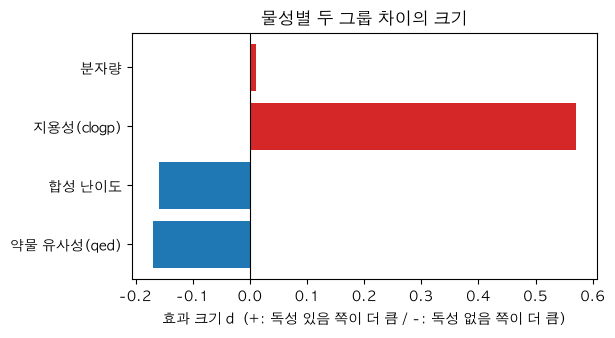

In [4]:
rows=[]
for c in NUM:
    a=train[train[TARGET]==0][c]; b=train[train[TARGET]==1][c]
    d=(a.mean()-b.mean())/np.sqrt((a.var()+b.var())/2)
    p=stats.mannwhitneyu(a,b).pvalue
    rows.append([nm[c],round(a.mean(),3),round(b.mean(),3),round(d,2),'%.1e'%p,'유의' if p<0.05 else '무관'])
tab=pd.DataFrame(rows,columns=['물성','독성있음 평균','독성없음 평균','효과크기 d','p값','판정'])
display(tab)
plt.figure(figsize=(6,3.2))
ds=[float(r[3]) for r in rows]
plt.barh([r[0] for r in rows][::-1], ds[::-1], color=[C0 if x>0 else C1 for x in ds[::-1]])
plt.axvline(0,color='k',lw=.8); plt.xlabel('효과 크기 d  (+: 독성 있음 쪽이 더 큼 / -: 독성 없음 쪽이 더 큼)'); plt.title('물성별 두 그룹 차이의 크기'); plt.show()

#### 그래프 1 · 물성별 두 그룹 차이의 크기
- **발견**: 지용성(clogp)만 두 그룹의 차이가 중간 크기이고, 나머지는 작거나 없습니다. 막대가 **오른쪽(+, 빨강)이면 독성 있음 쪽 값이 더 크다**는 뜻입니다.
- **근거**: 효과 크기 d = 지용성 **+0.57**, 합성 난이도 -0.16, 약물 유사성 -0.17, 분자량 **+0.01**(p=0.40, 차이 없음). 평균은 지용성이 독성 있음 4.21 vs 없음 3.45입니다.
- **이유**: 지용성이 높을수록 독성 있음 쪽에 많다는 것은 데이터에서 확인한 사실입니다. 왜 그런지(기름에 잘 녹는 물질이 몸 안 여러 곳에 달라붙거나 쌓이기 쉽다는 설명)는 일반적인 화학 상식이며, 이 데이터가 증명한 것은 아닙니다.
- **의미**: 모델이 가장 먼저 믿을 만한 물성은 지용성입니다. 분자량은 독성 구분에 거의 쓸모가 없습니다. p값이 작아도 d가 작으면 영향이 작다는 점에 주의하세요(합성 난이도, 약물 유사성).

## 2. 물성 ↔ 독성: 분포를 겹쳐 보기 (바이올린 · 밀도)

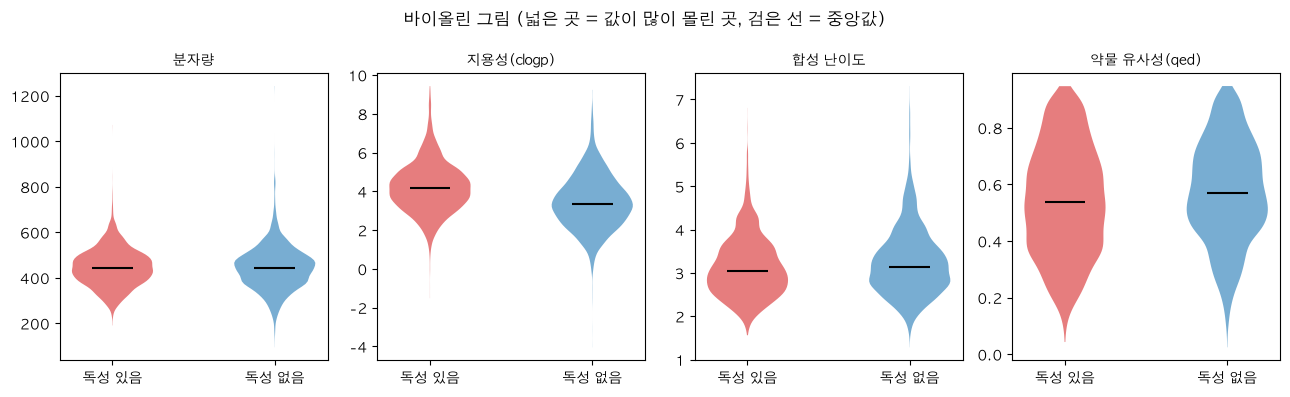

In [5]:
fig,ax=plt.subplots(1,4,figsize=(13,4))
for a,c in zip(ax,NUM):
    vp=a.violinplot([train[train[TARGET]==0][c],train[train[TARGET]==1][c]],showmedians=True,showextrema=False)
    for b,col in zip(vp['bodies'],[C0,C1]): b.set_facecolor(col); b.set_alpha(.6)
    vp['cmedians'].set_color('k')
    a.set_xticks([1,2]); a.set_xticklabels(['독성 있음','독성 없음']); a.set_title(nm[c],fontsize=10)
plt.suptitle('바이올린 그림 (넓은 곳 = 값이 많이 몰린 곳, 검은 선 = 중앙값)'); plt.tight_layout(); plt.show()

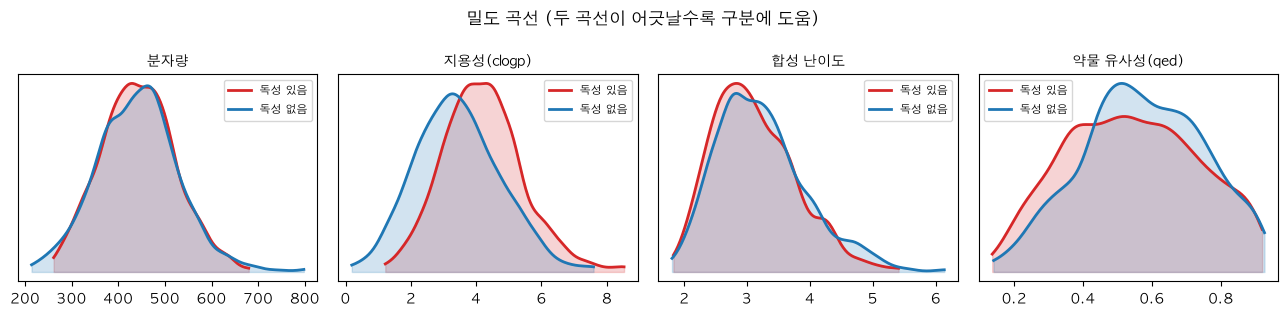

In [6]:
fig,ax=plt.subplots(1,4,figsize=(13,3.2))
for a,c in zip(ax,NUM):
    for l,col,n in [(0,C0,'독성 있음'),(1,C1,'독성 없음')]:
        s=train[train[TARGET]==l][c]; xs=np.linspace(s.quantile(.005),s.quantile(.995),200)
        a.plot(xs,stats.gaussian_kde(s)(xs),color=col,label=n,lw=2); a.fill_between(xs,stats.gaussian_kde(s)(xs),color=col,alpha=.2)
    a.set_title(nm[c],fontsize=10); a.legend(fontsize=8); a.set_yticks([])
plt.suptitle('밀도 곡선 (두 곡선이 어긋날수록 구분에 도움)'); plt.tight_layout(); plt.show()

#### 그래프 2 · 바이올린 그림 / 그래프 3 · 밀도 곡선
- **발견**: 지용성에서만 빨강(독성 있음)이 오른쪽(큰 값)으로 확실히 치우칩니다. 합성 난이도·약물 유사성은 조금 어긋나고, 분자량은 거의 겹칩니다.
- **근거**: 중앙값이 지용성 4.15(독성 있음) vs 3.37(독성 없음), 합성 난이도 3.03 vs 3.14, 약물 유사성 0.538 vs 0.571, 분자량 441.0 vs 441.7입니다.
- **이유**: 평균(그래프 1)이 같은 방향의 차이를 보였고, 그림은 그 차이가 일부 이상치 때문이 아니라 분포 전체가 옮겨간 결과임을 보여 줍니다.
- **의미**: 다만 지용성도 두 곡선이 **많이 겹칩니다.** 지용성 하나만으로는 독성을 확정할 수 없고 "확률이 달라지는 정도"의 단서입니다.

## 3. 물성 ↔ 독성: 값이 커질수록 독성 있음 비율은 어떻게 변하나
물성을 10구간으로 나누어 **독성 있음 비율**의 변화를 선으로 이어 봅니다. (오차 막대 = 불확실한 범위, 95%)

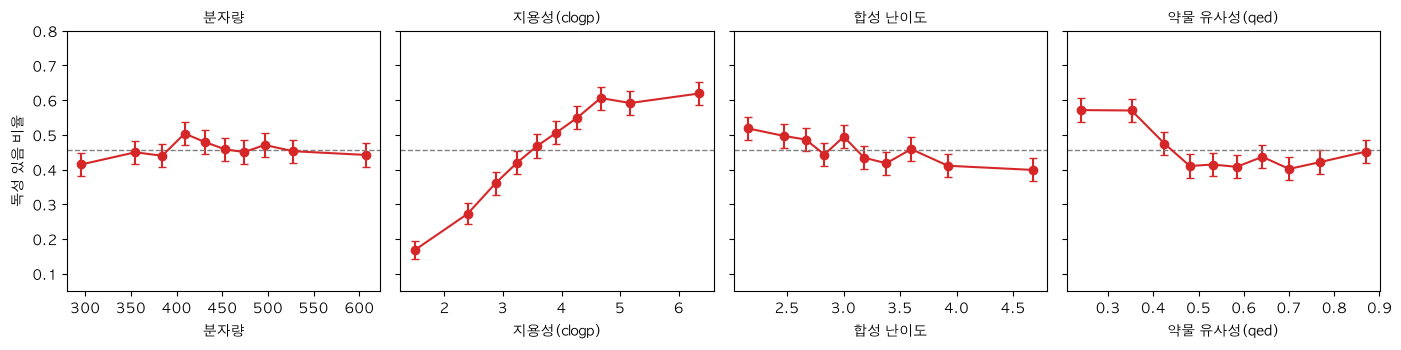

In [7]:
fig,ax=plt.subplots(1,4,figsize=(14,3.6),sharey=True)
for a,c in zip(ax,NUM):
    g=train.groupby(pd.qcut(train[c],10,duplicates='drop'),observed=True)
    m=1-g[TARGET].mean().values; n=g.size().values; se=1.96*np.sqrt(m*(1-m)/n)
    x=g[c].mean().values
    a.errorbar(x,m,yerr=se,fmt='o-',color=C0,capsize=3); a.axhline(1-train[TARGET].mean(),color='gray',ls='--',lw=1)
    a.set_title(nm[c],fontsize=10); a.set_xlabel(nm[c]); a.set_ylim(.05,.8)
ax[0].set_ylabel('독성 있음 비율')
plt.tight_layout(); plt.show()

#### 그래프 4 · 10구간별 독성 있음 비율
- **발견**: 지용성이 커질수록 독성 있음 비율이 꾸준히 **올라갑니다.** 약물 유사성은 아주 낮은 구간만 높습니다. 분자량은 평평합니다.
- **근거**: 지용성 10구간의 독성 있음 비율은 **17% → 27 → 36 → 42 → 47 → 51 → 55 → 61 → 59 → 62%**로 증가합니다(전체 평균 46%). 약물 유사성은 가장 낮은 두 구간이 57%이고 나머지는 약 40~47%입니다. 합성 난이도는 52%에서 40%로 완만히 내려갑니다. 분자량은 41~50% 사이에서 일정한 방향이 없습니다.
- **이유**: 평균 차이만 보면 안 보이는 **모양**(꾸준한 증가 / 낮은 구간에서만 상승 / 평평함)을 구간별로 나눠 보면 알 수 있습니다. 오차 막대가 작아서 구간 간 차이는 우연이 아닙니다. 이 그래프는 그래프 3(밀도 곡선)에서 빨강이 오른쪽으로 치우친 것과 **같은 내용**입니다.
- **의미**: 지용성은 직선에 가까운 단조 관계라 모델이 쓰기 좋습니다. 약물 유사성은 "낮으면 위험"이라는 **임계 효과**라서 직선 모델보다 트리 계열 모델이 더 잘 잡을 수 있습니다. 지용성 약 4.5 이상(8구간부터)은 더 오르지 않고 59~62%에서 머뭅니다.

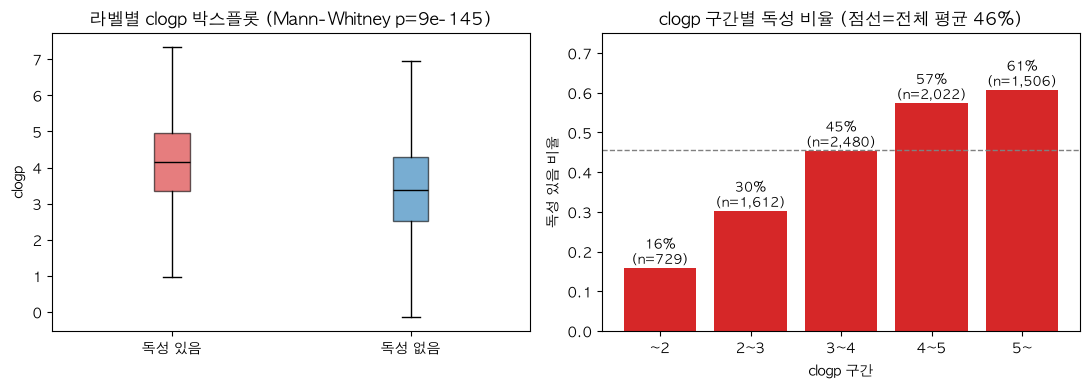

중앙값 독성 있음 4.15 vs 독성 없음 3.37


In [8]:
# 보충 A. clogp: 라벨별 박스플롯 + clogp 구간별 독성 비율
g0=train[train[TARGET]==0].clogp; g1=train[train[TARGET]==1].clogp
pv=stats.mannwhitneyu(g0,g1).pvalue
tox=1-train[TARGET]
cut=pd.cut(train.clogp,[-99,2,3,4,5,99],labels=['~2','2~3','3~4','4~5','5~'])
g=tox.groupby(cut,observed=True).agg(['mean','size'])
fig,ax=plt.subplots(1,2,figsize=(11,4))
bp=ax[0].boxplot([g0,g1],tick_labels=[LABEL_NAME[0],LABEL_NAME[1]],patch_artist=True,showfliers=False)
for bx,col in zip(bp['boxes'],[C0,C1]): bx.set_facecolor(col); bx.set_alpha(.6)
for md in bp['medians']: md.set_color('k')
ax[0].set_ylabel('clogp'); ax[0].set_title(f'라벨별 clogp 박스플롯 (Mann-Whitney p={pv:.0e})')
ax[1].bar(g.index.astype(str),g['mean'],color=C0); ax[1].axhline(tox.mean(),color='gray',ls='--',lw=1)
for i,(m_,n_) in enumerate(zip(g['mean'],g['size'])): ax[1].text(i,m_+.01,f'{m_:.0%}\n(n={n_:,})',ha='center',fontsize=9)
ax[1].set_ylim(0,.75); ax[1].set_xlabel('clogp 구간'); ax[1].set_ylabel('독성 있음 비율'); ax[1].set_title(f'clogp 구간별 독성 비율 (점선=전체 평균 {tox.mean():.0%})')
plt.tight_layout(); plt.show()
print('중앙값 독성 있음 %.2f vs 독성 없음 %.2f'%(g0.median(),g1.median()))

##### 핵심 분석 ① clogp (지용성)
**발견**
- clogp 중앙값: 독성 있음 4.15 vs 독성 없음 3.37
- clogp 구간이 올라갈수록 독성 비율이 꾸준히 증가 (전체 평균 46%)

| clogp 구간 | ~2 | 2~3 | 3~4 | 4~5 | 5~ |
| --- | --- | --- | --- | --- | --- |
| 독성 비율 | 16% | 30% | 45% | 57% | 61% |

**근거**
- 라벨별 clogp 박스플롯, Mann-Whitney 검정 p≈1e-145
- clogp 구간별 독성 비율 막대그래프 (위 그래프)

**이유 (추정)**
- 지용성이 높은 물질은 세포막을 쉽게 통과하고 몸에 쌓이기 쉬워 독성으로 이어질 수 있음
- 약물 설계 기준(Lipinski 규칙)에서도 clogp 5 이하를 권장

**의미**
- clogp는 핵심 피처 → 모델에 반드시 포함
- 분자 특성 4개 중 독성과 가장 강하게 연관됨

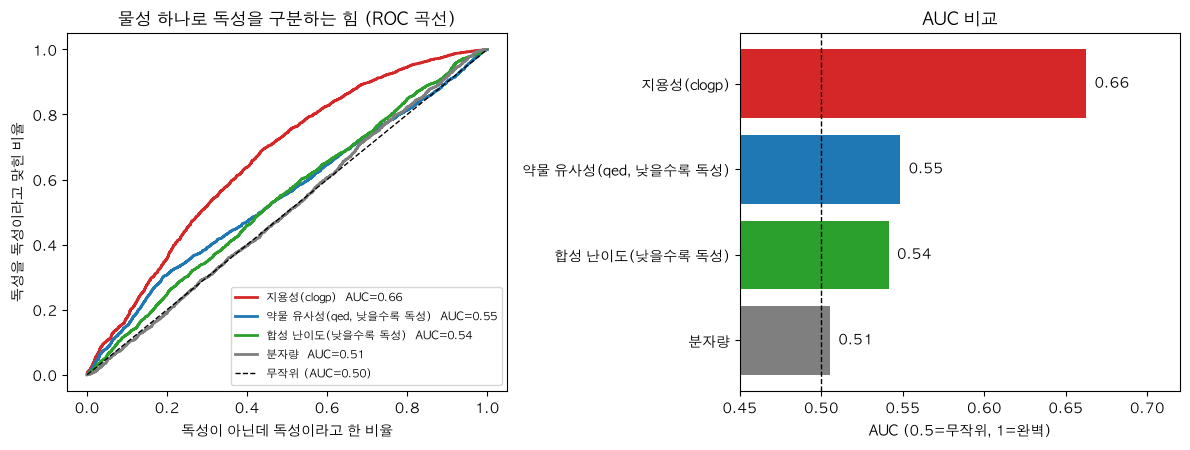

clogp가 1 오를 때 독성이 될 가능성(odds)은 1.54배


In [9]:
# 지용성 ①-2. 단독 예측력: ROC 곡선과 AUC
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
tox=1-train[TARGET]
cands={'지용성(clogp)':train.clogp,'약물 유사성(qed, 낮을수록 독성)':-train.qed,'합성 난이도(낮을수록 독성)':-train.sa_score,'분자량':train.MolWt}
cols=['#d62728','#1f77b4','#2ca02c','#7f7f7f']
fig,ax=plt.subplots(1,2,figsize=(12,4.6)); aucs={}
for (k,v),col in zip(cands.items(),cols):
    fpr,tpr,_=roc_curve(tox,v); aucs[k]=roc_auc_score(tox,v); ax[0].plot(fpr,tpr,color=col,lw=2,label=f'{k}  AUC={aucs[k]:.2f}')
ax[0].plot([0,1],[0,1],'k--',lw=1,label='무작위 (AUC=0.50)')
ax[0].set_xlabel('독성이 아닌데 독성이라고 한 비율'); ax[0].set_ylabel('독성을 독성이라고 맞힌 비율'); ax[0].legend(fontsize=8,loc='lower right'); ax[0].set_title('물성 하나로 독성을 구분하는 힘 (ROC 곡선)')
ax[1].barh(list(aucs)[::-1],list(aucs.values())[::-1],color=cols[::-1]); ax[1].axvline(.5,color='k',ls='--',lw=1)
for i,v in enumerate(list(aucs.values())[::-1]): ax[1].text(v+.005,i,f'{v:.2f}',va='center')
ax[1].set_xlim(.45,.72); ax[1].set_xlabel('AUC (0.5=무작위, 1=완벽)'); ax[1].set_title('AUC 비교')
plt.tight_layout(); plt.show()
m1=LogisticRegression(C=1e6,max_iter=1000).fit(train[['clogp']].values.astype(float),tox)
print('clogp가 1 오를 때 독성이 될 가능성(odds)은 %.2f배'%np.exp(m1.coef_[0][0]))

##### 핵심 분석 ①-2 지용성의 단독 예측력
**발견**
- clogp 하나만으로 독성을 구분하는 힘(AUC)은 **0.66**: 4개 물성 중 가장 높음 (qed 0.55, 합성 난이도 0.54, 분자량 0.51)
- clogp가 1 오를 때마다 독성이 될 가능성(odds)이 **약 1.54배**
- 그래도 0.66은 단독으로는 약함 (0.5=무작위, 1=완벽)

**근거**
- ROC 곡선: clogp 곡선만 대각선(무작위)에서 뚜렷이 위로 벗어나고, 나머지 물성은 대각선에 가까움
- AUC 막대 비교

**이유 (추정)**
- AUC 0.66은 "독성 화합물 하나와 비독성 화합물 하나를 뽑으면 독성 쪽의 clogp가 더 클 확률이 약 66%"라는 뜻. 두 그룹의 clogp 분포가 많이 겹치기 때문에(그래프 3) 이 정도에 머묾

**의미**
- clogp는 핵심 피처이지만 단독으로 독성을 판정하기에는 부족 → 지문 등 다른 정보와 함께 써야 함 (물성 4개만 쓸 때 F1 0.70, 지문 포함 시 0.82)
- qed, 합성 난이도, 분자량은 단독 예측력이 거의 없음

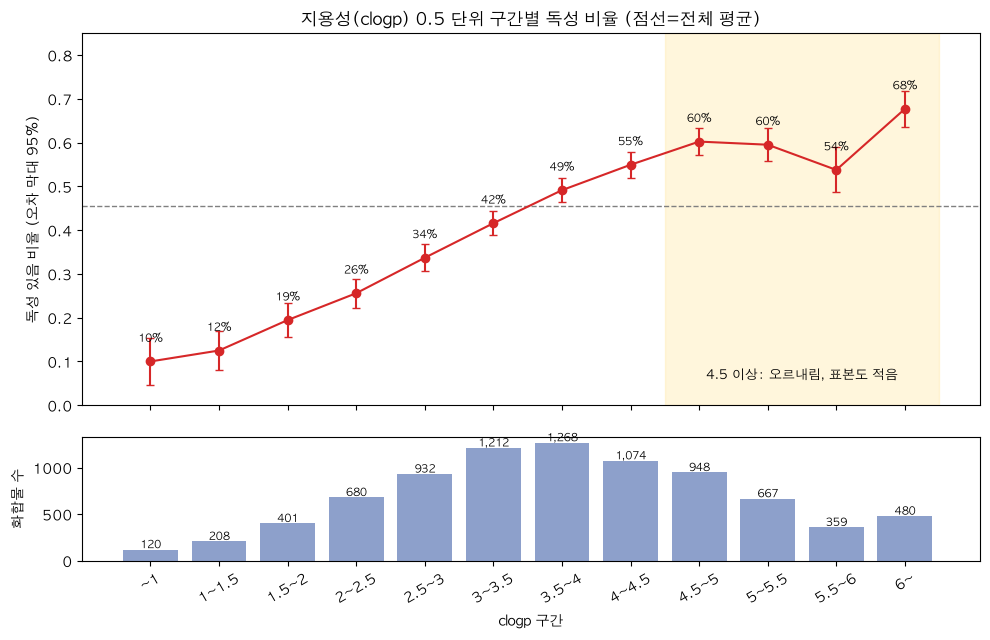

In [10]:
# 지용성 ①-3. 지용성을 잘게 나눈 독성 비율 (모양 확인)
x=train.clogp
edges=[-5,1,1.5,2,2.5,3,3.5,4,4.5,5,5.5,6,10]
labs=['~1','1~1.5','1.5~2','2~2.5','2.5~3','3~3.5','3.5~4','4~4.5','4.5~5','5~5.5','5.5~6','6~']
g=tox.groupby(pd.cut(x,edges,labels=labs),observed=True).agg(['mean','size'])
ci=1.96*np.sqrt(g['mean']*(1-g['mean'])/g['size'])
fig,ax=plt.subplots(2,1,figsize=(10,6.5),sharex=True,gridspec_kw={'height_ratios':[3,1]})
ax[0].errorbar(range(len(g)),g['mean'],yerr=ci,fmt='o-',color=C0,capsize=3); ax[0].axhline(tox.mean(),color='gray',ls='--',lw=1)
for i,v in enumerate(g['mean']): ax[0].text(i,v+.045,f'{v:.0%}',ha='center',fontsize=8)
ax[0].axvspan(7.5,11.5,color='#ffe9a8',alpha=.4); ax[0].text(9.5,.06,'4.5 이상: 오르내림, 표본도 적음',ha='center',fontsize=9)
ax[0].set_ylim(0,.85); ax[0].set_ylabel('독성 있음 비율 (오차 막대 95%)'); ax[0].set_title('지용성(clogp) 0.5 단위 구간별 독성 비율 (점선=전체 평균)')
ax[1].bar(range(len(g)),g['size'],color='#8da0cb'); ax[1].set_ylabel('화합물 수')
for i,v in enumerate(g['size']): ax[1].text(i,v+15,f'{v:,}',ha='center',fontsize=8)
ax[1].set_xticks(range(len(g))); ax[1].set_xticklabels(labs,rotation=30); ax[1].set_xlabel('clogp 구간')
plt.tight_layout(); plt.show()

##### 핵심 분석 ①-3 지용성 구간별 모양
**발견**
- 지용성이 낮은 쪽은 안전: clogp 1 이하는 독성 **10%** (n=120), 1~1.5는 12.5%
- 4.5까지는 구간(0.5 단위)마다 약 5~8%p씩 거의 꾸준히 상승: 19% → 26% → 34% → 42% → 49% → 55% → 60%
- 4.5 이후에는 상승이 멈추고 **오르내림**: 60% → 60% → 54% → 6 이상 68%

**근거**
- 구간별 독성 비율과 오차 막대, 구간별 화합물 수 (위 그래프)
- 4.5 이상 구간은 화합물 수가 줄어(359~948개) 오차 막대가 ±3~5%p로 커서, 구간 사이 차이(예: 54% vs 60%)를 단정하기 어려움

**이유 (추정)**
- 물에 잘 녹는 분자는 몸에 쌓이지 않고 배출되기 쉬워 안전한 쪽에 많을 수 있음 (일반 상식, 이 데이터가 증명한 것은 아님)
- 높은 쪽의 정체는 지용성 외의 요인이 더 크게 작용하거나 표본이 적어서일 수 있으나 이 데이터로는 구분 불가

**의미**
- 지용성 효과는 완전한 직선이 아니라 4.5 근처에서 둔해지는 모양 → 트리 계열 모델이 이런 구간 구조를 잘 잡음
- 낮은 지용성(약 2 이하, 독성 20% 이하)은 비교적 확실한 안전 신호, 높은 쪽 극단값(6 이상)의 해석은 신중하게

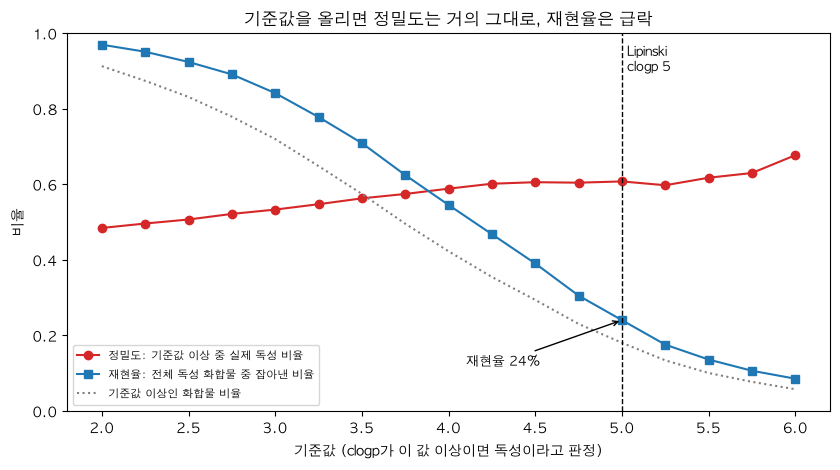

기준값 3: 정밀도 53.3% | 재현율 84.1% | 해당 화합물 72%
기준값 3.5: 정밀도 56.3% | 재현율 70.9% | 해당 화합물 57%
기준값 4: 정밀도 58.8% | 재현율 54.5% | 해당 화합물 42%
기준값 4.5: 정밀도 60.6% | 재현율 39.0% | 해당 화합물 29%
기준값 5: 정밀도 60.8% | 재현율 24.0% | 해당 화합물 18%


In [11]:
# 지용성 ①-4. 기준값을 정해 독성을 가르면? (정밀도 vs 재현율)
ths=np.arange(2,6.01,.25); pr=[];rc=[];sh=[]
for th in ths:
    sel=x>=th; pr.append(tox[sel].mean()); rc.append(tox[sel].sum()/tox.sum()); sh.append(sel.mean())
fig,ax=plt.subplots(figsize=(8.5,4.8))
ax.plot(ths,pr,'o-',color=C0,label='정밀도: 기준값 이상 중 실제 독성 비율')
ax.plot(ths,rc,'s-',color=C1,label='재현율: 전체 독성 화합물 중 잡아낸 비율')
ax.plot(ths,sh,':',color='gray',label='기준값 이상인 화합물 비율')
ax.axvline(5,color='k',ls='--',lw=1); ax.text(5.03,.9,'Lipinski\nclogp 5',fontsize=9)
k5=list(ths).index(5.0); ax.annotate(f'재현율 {rc[k5]:.0%}',(5,rc[k5]),xytext=(4.1,.12),arrowprops=dict(arrowstyle='->'),fontsize=9)
ax.set_xlabel('기준값 (clogp가 이 값 이상이면 독성이라고 판정)'); ax.set_ylabel('비율'); ax.set_ylim(0,1); ax.legend(fontsize=8,loc='lower left'); ax.set_title('기준값을 올리면 정밀도는 거의 그대로, 재현율은 급락')
plt.tight_layout(); plt.show()
for th in [3,3.5,4,4.5,5]:
    sel=x>=th; print(f'기준값 {th}: 정밀도 {tox[sel].mean():.1%} | 재현율 {tox[sel].sum()/tox.sum():.1%} | 해당 화합물 {sel.mean():.0%}')

##### 핵심 분석 ①-4 "clogp 5 이하" 기준은 얼마나 쓸모 있나
**발견**
- clogp 5를 넘으면 독성 61%, 5 이하는 42%로 차이는 분명함
- 그러나 5를 넘는 화합물은 전체의 18%뿐이고, **독성 화합물의 24%만** 잡아냄 → 나머지 76%는 clogp 5 이하
- 기준값을 올려도 정밀도는 거의 그대로인데(53% → 61%) 재현율만 급락(84% → 24%)

| 기준값 | 3 | 3.5 | 4 | 4.5 | 5 |
| --- | --- | --- | --- | --- | --- |
| 정밀도 (기준값 이상 중 독성) | 53% | 56% | 59% | 61% | 61% |
| 재현율 (독성 중 잡은 비율) | 84% | 71% | 55% | 39% | 24% |
| 해당 화합물 비율 | 72% | 57% | 42% | 29% | 18% |

**근거**
- 기준값별 정밀도·재현율 곡선

**이유 (추정)**
- 독성은 지용성 외에도 구조 등 여러 요인에 좌우되고, 독성/비독성 화합물의 지용성 분포가 많이 겹쳐서(그래프 3) 기준 하나로는 가를 수 없음

**의미**
- "clogp 5 이하면 안전"은 이 데이터에서 성립하지 않음 (5 이하에도 독성 화합물이 대부분). Lipinski 기준은 참고 정도로만 사용
- 지용성은 단독 필터가 아니라 모델의 입력 피처로 써야 함

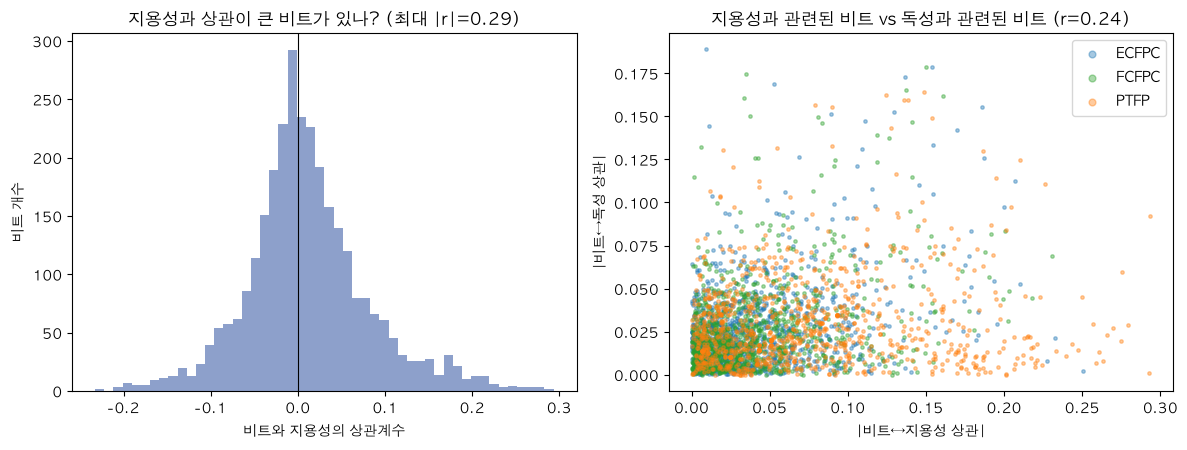

지용성과 상관이 가장 큰 비트 5개: {'ptfp_242': 0.29, 'ptfp_741': 0.29, 'ptfp_20': 0.28, 'ptfp_567': 0.28, 'ptfp_185': 0.27}
|r|>0.3 인 비트 수: 0


In [12]:
# 지용성 ①-5. 지용성과 지문 비트의 관계
cb=train_chiral[FP_CHIRAL].corrwith(train_chiral.clogp).dropna()
lb=train_chiral[FP_CHIRAL].corrwith(tox).dropna()
typ=pd.Series([c.split('_')[0] for c in cb.index],index=cb.index)
tc_={'ecfpc':'#1f77b4','fcfpc':'#2ca02c','ptfp':'#ff7f0e'}
fig,ax=plt.subplots(1,2,figsize=(12,4.6))
ax[0].hist(cb,bins=50,color='#8da0cb'); ax[0].axvline(0,color='k',lw=.8)
ax[0].set_xlabel('비트와 지용성의 상관계수'); ax[0].set_ylabel('비트 개수'); ax[0].set_title(f'지용성과 상관이 큰 비트가 있나? (최대 |r|={cb.abs().max():.2f})')
for k,col in tc_.items():
    ii=typ[typ==k].index; ax[1].scatter(cb[ii].abs(),lb[ii].abs(),s=6,alpha=.4,color=col,label=k.upper())
ax[1].set_xlabel('|비트↔지용성 상관|'); ax[1].set_ylabel('|비트↔독성 상관|'); ax[1].legend(markerscale=2)
ax[1].set_title(f'지용성과 관련된 비트 vs 독성과 관련된 비트 (r={np.corrcoef(cb.abs(),lb.abs().reindex(cb.index))[0,1]:.2f})')
plt.tight_layout(); plt.show()
top=cb.reindex(cb.abs().sort_values(ascending=False).index).head(5); print('지용성과 상관이 가장 큰 비트 5개:',top.round(2).to_dict()); print('|r|>0.3 인 비트 수:',int((cb.abs()>.3).sum()))

##### 핵심 분석 ①-5 지용성과 지문 비트
**발견**
- 지용성과 상관이 가장 큰 지문 비트도 |r| **0.29**로, 0.3을 넘는 비트가 없음 (상위는 대부분 PTFP)
- "지용성과 관련된 비트"와 "독성과 관련된 비트"는 별로 겹치지 않음 (두 상관의 크기끼리 r=0.24)

**근거**
- 왼쪽: 비트↔지용성 상관계수 분포가 0 근처에 몰림
- 오른쪽: 두 상관의 크기를 점으로 찍으면 한쪽만 큰 비트가 대부분

**이유 (추정)**
- 지용성은 분자 전체의 성질이라 특정 부분 구조 하나로는 거의 표현되지 않을 가능성이 큼 (비트가 어떤 구조인지는 이 데이터로 알 수 없음)

**의미**
- 지문 비트 하나하나로는 지용성을 대신 설명하지 못하므로, 지용성은 지문과 **별도 정보**로 보임 → 모델에 따로 넣을 이유가 됨
- 다만 여러 비트를 조합하면 지용성을 설명할 수도 있으며, 모델에서 실제로 추가 이득이 있는지는 검증하지 않음

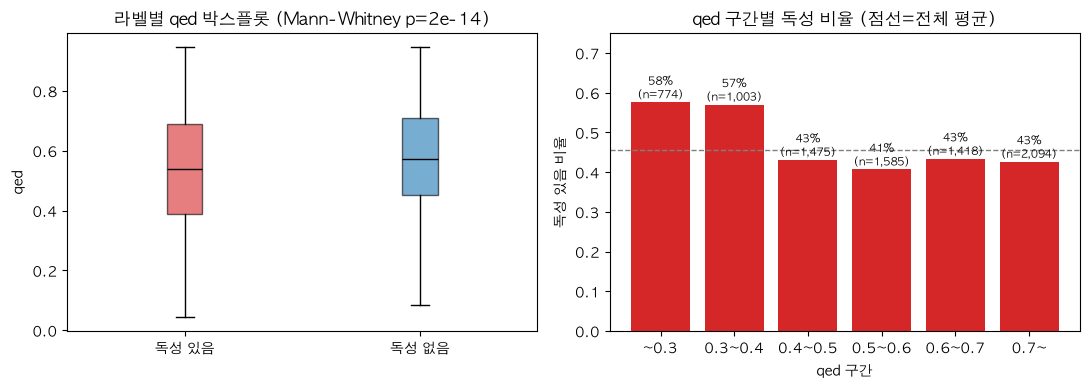

중앙값 독성 있음 0.538 vs 독성 없음 0.571
qed<0.4: 독성 57.3% (n=1777) / qed>=0.4: 독성 42.4%


In [13]:
# 보충 B. qed: 라벨별 박스플롯 + qed 구간별 독성 비율
q0=train[train[TARGET]==0].qed; q1=train[train[TARGET]==1].qed
pv=stats.mannwhitneyu(q0,q1).pvalue
cut=pd.cut(train.qed,[0,.3,.4,.5,.6,.7,1],labels=['~0.3','0.3~0.4','0.4~0.5','0.5~0.6','0.6~0.7','0.7~'])
g=tox.groupby(cut,observed=True).agg(['mean','size'])
fig,ax=plt.subplots(1,2,figsize=(11,4))
bp=ax[0].boxplot([q0,q1],tick_labels=[LABEL_NAME[0],LABEL_NAME[1]],patch_artist=True,showfliers=False)
for bx,col in zip(bp['boxes'],[C0,C1]): bx.set_facecolor(col); bx.set_alpha(.6)
for md in bp['medians']: md.set_color('k')
ax[0].set_ylabel('qed'); ax[0].set_title(f'라벨별 qed 박스플롯 (Mann-Whitney p={pv:.0e})')
ax[1].bar(g.index.astype(str),g['mean'],color=C0); ax[1].axhline(tox.mean(),color='gray',ls='--',lw=1)
for i,(m_,n_) in enumerate(zip(g['mean'],g['size'])): ax[1].text(i,m_+.01,f'{m_:.0%}\n(n={n_:,})',ha='center',fontsize=8)
ax[1].set_ylim(0,.75); ax[1].set_xlabel('qed 구간'); ax[1].set_ylabel('독성 있음 비율'); ax[1].set_title('qed 구간별 독성 비율 (점선=전체 평균)')
plt.tight_layout(); plt.show()
print('중앙값 독성 있음 %.3f vs 독성 없음 %.3f'%(q0.median(),q1.median()))
print('qed<0.4: 독성 %.1f%% (n=%d) / qed>=0.4: 독성 %.1f%%'%(100*tox[train.qed<.4].mean(),(train.qed<.4).sum(),100*tox[train.qed>=.4].mean()))

##### 핵심 분석 ② qed (약물 유사성)
**발견**
- qed 중앙값: 독성 있음 0.538 vs 독성 없음 0.571 (차이 작음)
- qed가 **0.4 미만**일 때만 독성 비율이 올라감: 0.4 미만 57% (n=1,777) vs 0.4 이상 42%

| qed 구간 | ~0.3 | 0.3~0.4 | 0.4~0.5 | 0.5~0.6 | 0.6~0.7 | 0.7~ |
| --- | --- | --- | --- | --- | --- | --- |
| 독성 비율 | 58% | 57% | 43% | 41% | 43% | 43% |

**근거**
- 라벨별 qed 박스플롯, Mann-Whitney 검정 p≈2e-14 (하지만 효과 크기 d≈0.17로 작음)
- qed 구간별 독성 비율 막대그래프 (위 그래프)

**이유 (추정)**
- qed가 낮다는 것은 기존 약물과 다른 특성을 가진다는 뜻이고, 그런 분자는 안전성이 확인된 약물 범위를 벗어난 것일 수 있음
- 다만 qed가 높아도 독성이 낮아지지는 않음(0.4 이상은 거의 평평) → "낮으면 위험"만 있고 "높으면 안전"은 아님

**의미**
- 직선 관계가 아니라 **임계값(약 0.4)** 형태의 효과 → 트리 계열 모델이 잘 잡아냄
- 단독 영향은 clogp보다 훨씬 작아 보조 피처로 사용

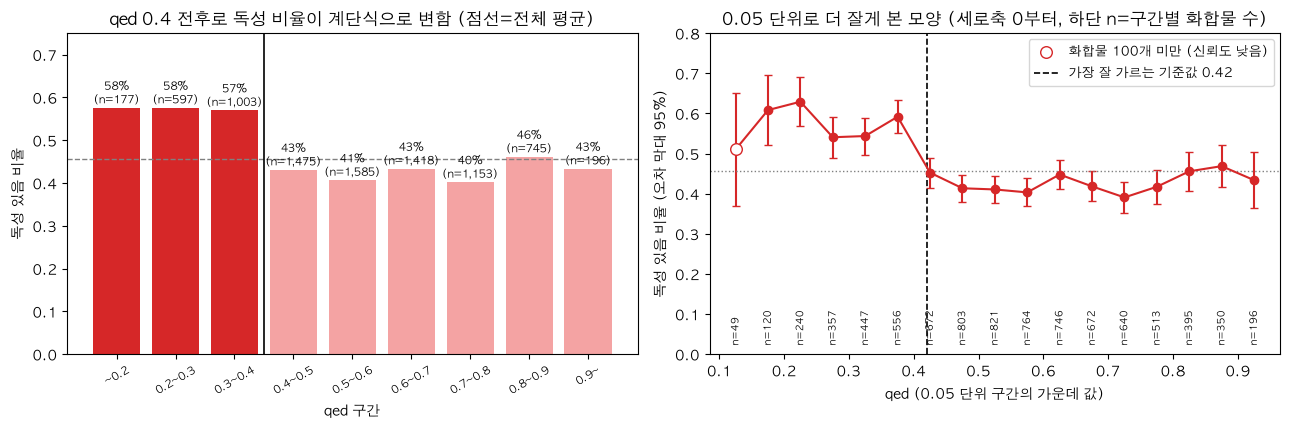

가장 잘 가르는 기준값 0.42 → 미만 57.0% (n=2016) / 이상 42.0% (n=6333)
이 기준 하나로 설명되는 독성 변동 비율: 1.7%


In [14]:
# 보충 B2. qed 임계 효과: 0.1 단위 구간 + 0.05 단위 선 + 가장 잘 가르는 기준값
tox=1-train[TARGET]
fig,ax=plt.subplots(1,2,figsize=(13,4.4))
edges=[0,.2,.3,.4,.5,.6,.7,.8,.9,1]
labs=['~0.2','0.2~0.3','0.3~0.4','0.4~0.5','0.5~0.6','0.6~0.7','0.7~0.8','0.8~0.9','0.9~']
g=tox.groupby(pd.cut(train.qed,edges,labels=labs),observed=True).agg(['mean','size'])
ax[0].bar(range(len(g)),g['mean'],color=[C0 if i<3 else '#f4a3a3' for i in range(len(g))])
ax[0].axhline(tox.mean(),color='gray',ls='--',lw=1); ax[0].axvline(2.5,color='k',lw=1.2)
for i,(m_,n_) in enumerate(zip(g['mean'],g['size'])): ax[0].text(i,m_+.01,f'{m_:.0%}\n(n={n_:,})',ha='center',fontsize=8)
ax[0].set_xticks(range(len(g))); ax[0].set_xticklabels(labs,rotation=30,fontsize=8); ax[0].set_ylim(0,.75)
ax[0].set_xlabel('qed 구간'); ax[0].set_ylabel('독성 있음 비율'); ax[0].set_title('qed 0.4 전후로 독성 비율이 계단식으로 변함 (점선=전체 평균)')
fe=np.arange(.1,.96,.05); gm=[];ge=[];mid=[];gn=[]
for a,b in zip(fe[:-1],fe[1:]):
    s=tox[(train.qed>=a)&(train.qed<b)]
    if len(s)>=30: gm.append(s.mean()); ge.append(1.96*np.sqrt(s.mean()*(1-s.mean())/len(s))); mid.append((a+b)/2); gn.append(len(s))
ax[1].errorbar(mid,gm,yerr=ge,fmt='o-',color=C0,capsize=3)
small=[i for i,n_ in enumerate(gn) if n_<100]
ax[1].scatter([mid[i] for i in small],[gm[i] for i in small],s=70,facecolors='white',edgecolors=C0,zorder=5,label='화합물 100개 미만 (신뢰도 낮음)')
for x_,n_ in zip(mid,gn): ax[1].text(x_,0.03,f'n={n_}',rotation=90,ha='center',fontsize=7)
ax[1].set_ylim(0,.8)
best=None
for th in np.arange(.2,.8,.01):
    lo=tox[train.qed<th]; hi=tox[train.qed>=th]
    if len(lo)<200 or len(hi)<200: continue
    gain=(len(lo)*(lo.mean()-tox.mean())**2+len(hi)*(hi.mean()-tox.mean())**2)/len(tox)
    if best is None or gain>best[0]: best=(gain,th,lo.mean(),hi.mean(),len(lo),len(hi))
ax[1].axvline(best[1],color='k',ls='--',lw=1.2,label=f'가장 잘 가르는 기준값 {best[1]:.2f}')
ax[1].axhline(tox.mean(),color='gray',ls=':',lw=1); ax[1].legend(fontsize=9)
ax[1].set_xlabel('qed (0.05 단위 구간의 가운데 값)'); ax[1].set_ylabel('독성 있음 비율 (오차 막대 95%)'); ax[1].set_title('0.05 단위로 더 잘게 본 모양 (세로축 0부터, 하단 n=구간별 화합물 수)')
plt.tight_layout(); plt.show()
print('가장 잘 가르는 기준값 %.2f → 미만 %.1f%% (n=%d) / 이상 %.1f%% (n=%d)'%(best[1],100*best[2],best[4],100*best[3],best[5]))
print('이 기준 하나로 설명되는 독성 변동 비율: %.1f%%'%(100*best[0]/(tox.mean()*(1-tox.mean()))))

##### 핵심 분석 ②-2 qed 임계 효과를 뒷받침하는 그래프
**발견**
- qed 0.3~0.4 구간(57%)에서 0.4~0.5 구간(43%)으로 넘어갈 때 독성 비율이 **14%p 급락**
- 0.4 미만은 0.2~0.4 내내 57~58%로 평평하고, 0.4 이상도 40~46%로 평평 → 직선이 아니라 **계단 모양**
- 데이터로 찾은 가장 잘 가르는 기준값은 **0.42**: 미만 57.0% (n=2,016) vs 이상 42.0%

**근거**
- 그래프 4b·4c 왼쪽: 0.1 단위 구간별 막대 (검은 선이 0.4)
- 그래프 4c-2: 0.4 미만 vs 이상 두 그룹의 독성 비율과 95% 신뢰구간 (두 막대의 오차 막대가 겹치지 않음)
- 그래프 4c 오른쪽: 0.05 단위로 더 잘게 나눈 선 (오차 막대 95%), 점선이 기준값 0.42. 세로축을 0부터 그려서 변화 크기가 과장되지 않게 함
- **판정은 구간 하나가 아니라 묶어서**: qed 0.4 미만 전체(1,777개) 57.3% vs 0.4 이상(6,572개) 42.4%, 차이 14.8%p (95% 신뢰구간 12.3~17.4%p, p<1e-27)
- **주의**: qed 0.10~0.15 구간은 화합물이 49개뿐이라 오차가 ±14%p로 커서 51%라는 값만으로는 위험 여부를 말할 수 없음 (그래프에서 속이 빈 점)
- 그래프 4(10구간 선그래프)에서도 같은 모양

**이유 (추정)**
- qed가 낮다는 것은 기존 약물이 가진 성질 범위를 벗어났다는 뜻이고, 그 영역에 독성 구조가 더 많이 섞여 있을 가능성이 있음. 다만 어떤 성질이 원인인지는 이 데이터로 알 수 없음

**의미**
- 직선 관계가 아니라 구간 효과 → 트리 계열 모델이 잘 잡고, 선형 모델에는 'qed < 0.4' 같은 이진 변수를 파생해 쓸 수 있음
- 단, 이 기준 하나로 설명되는 독성 변동은 **약 1.7%** 로 작음 → 보조 신호이지 주력 피처는 아님

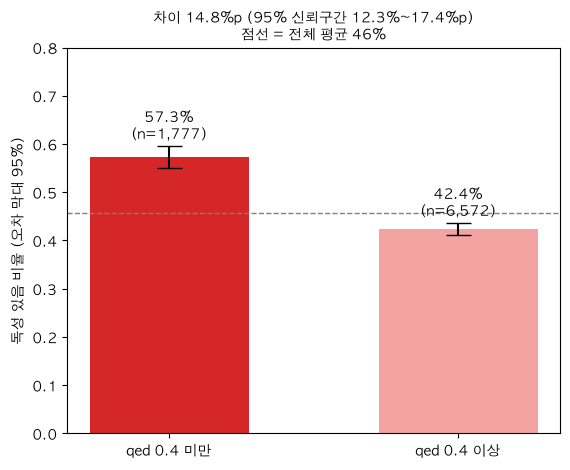

In [15]:
# 보충 B4. qed 0.4 미만 vs 이상: 두 그룹 독성 비율 비교 (95% 신뢰구간)
lo=tox[train.qed<.4]; hi=tox[train.qed>=.4]
ms=[lo.mean(),hi.mean()]; ns=[len(lo),len(hi)]
ci=[1.96*np.sqrt(m_*(1-m_)/n_) for m_,n_ in zip(ms,ns)]
d=ms[0]-ms[1]; se=np.sqrt(ms[0]*(1-ms[0])/ns[0]+ms[1]*(1-ms[1])/ns[1])
fig,ax=plt.subplots(figsize=(5.8,4.8))
ax.bar(['qed 0.4 미만','qed 0.4 이상'],ms,yerr=ci,capsize=9,color=[C0,'#f4a3a3'],width=.55)
ax.axhline(tox.mean(),color='gray',ls='--',lw=1)
for i,(m_,n_,c_) in enumerate(zip(ms,ns,ci)): ax.text(i,m_+c_+.015,f'{m_:.1%}\n(n={n_:,})',ha='center')
ax.set_ylim(0,.8); ax.set_ylabel('독성 있음 비율 (오차 막대 95%)')
ax.set_title(f'차이 {d:.1%}p (95% 신뢰구간 {d-1.96*se:.1%}~{d+1.96*se:.1%}p)\n점선 = 전체 평균 {tox.mean():.0%}',fontsize=10)
plt.tight_layout(); plt.show()

##### 핵심 분석 ③ MolWt (분자량)
**발견**
- MolWt 중앙값: 독성 있음 441.0 vs 독성 없음 441.7 → 사실상 동일
- 10구간으로 나눠도 독성 비율이 41~50% 사이에서 일정한 방향 없음

**근거**
- Mann-Whitney 검정 p≈0.40 (유의하지 않음), 효과 크기 d≈0.01
- 그래프 1(효과 크기), 그래프 2·3(분포), 그래프 4(구간별 비율) 참조

**이유 (추정)**
- 분자 크기 자체는 독성을 가르는 요인이 아닐 가능성이 큼 (독성은 어떤 구조·성질을 가졌느냐에 더 좌우됨)

**의미**
- 단독 피처로서의 가치는 낮음
- 단, 분자량은 qed·합성 난이도와 얽혀 있으므로(그래프 5~7) 제거 여부는 모델 성능을 비교해서 결정

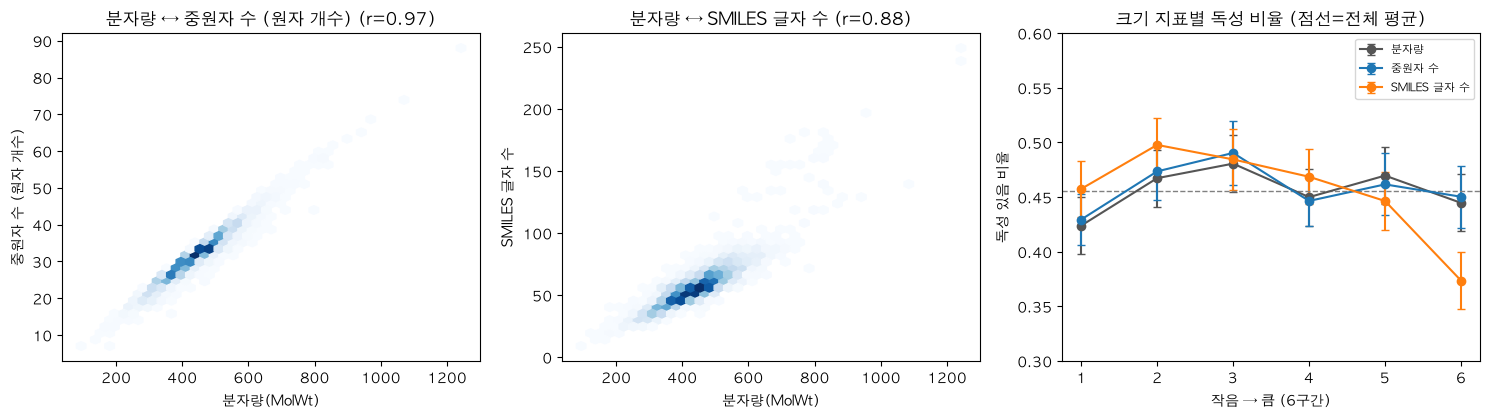

중원자 수 평균 31.5개 (최소 7, 최대 88)
원자 1개당 평균 질량 14.1 (표준편차 0.7)
분자량 ↔ 독성 상관 0.006
중원자 수 ↔ 독성 상관 0.007
SMILES 글자 수 ↔ 독성 상관 -0.065


In [16]:
# 보충 B3. 분자량 vs 분자 크기(중원자 수, SMILES 글자 수)
mols=train['SMILES'].apply(Chem.MolFromSmiles)
heavy=mols.apply(lambda m: m.GetNumHeavyAtoms())   # 중원자 수 = 수소를 뺀 원자 개수
slen=train['SMILES'].str.len()
tox=1-train[TARGET]
fig,ax=plt.subplots(1,3,figsize=(15,4.3))
for a,(v,nm_) in zip(ax[:2],[(heavy,'중원자 수 (원자 개수)'),(slen,'SMILES 글자 수')]):
    a.hexbin(train.MolWt,v,gridsize=40,cmap='Blues',mincnt=1)
    a.set_xlabel('분자량(MolWt)'); a.set_ylabel(nm_); a.set_title(f'분자량 ↔ {nm_} (r={np.corrcoef(train.MolWt,v)[0,1]:.2f})')
for v,lab,col in [(train.MolWt,'분자량','#555555'),(heavy,'중원자 수','#1f77b4'),(slen,'SMILES 글자 수','#ff7f0e')]:
    g=tox.groupby(pd.qcut(v,6,labels=False,duplicates='drop')).agg(['mean','size'])
    ax[2].errorbar(np.arange(len(g))+1,g['mean'],yerr=1.96*np.sqrt(g['mean']*(1-g['mean'])/g['size']),fmt='o-',color=col,capsize=3,label=lab)
ax[2].axhline(tox.mean(),color='gray',ls='--',lw=1); ax[2].set_ylim(.3,.6); ax[2].legend(fontsize=8)
ax[2].set_xlabel('작음 → 큼 (6구간)'); ax[2].set_ylabel('독성 있음 비율'); ax[2].set_title('크기 지표별 독성 비율 (점선=전체 평균)')
plt.tight_layout(); plt.show()
print('중원자 수 평균 %.1f개 (최소 %d, 최대 %d)'%(heavy.mean(),heavy.min(),heavy.max()))
per=train.MolWt/heavy; print('원자 1개당 평균 질량 %.1f (표준편차 %.1f)'%(per.mean(),per.std()))
for lab,v in [('분자량',train.MolWt),('중원자 수',heavy),('SMILES 글자 수',slen)]: print(lab,'↔ 독성 상관 %.3f'%np.corrcoef(v,tox)[0,1])

##### 핵심 분석 ③-2 분자량 vs 분자 크기
**용어**
- **분자량(MolWt)**: 분자를 이루는 원자들의 **질량 합**. 이 데이터의 열입니다.
- **분자 크기**: 분자가 얼마나 큰지, 보통 **원자가 몇 개 모여 있는지**(또는 차지하는 부피)를 뜻하는 일상적 표현입니다. 이 데이터에는 직접 열이 없어서, SMILES에서 **중원자 수**(수소를 뺀 원자 개수)와 **SMILES 글자 수**를 계산해 대신 비교했습니다.

**발견**
- 분자량과 중원자 수는 **사실상 같은 정보**: 상관 **0.97**, 원자 1개당 평균 질량 14.1(표준편차 0.7)
- SMILES 글자 수와도 상관 0.88로 높음
- 세 지표 모두 독성과 거의 무관: 상관 분자량 0.006, 중원자 수 0.007, SMILES 글자 수 -0.065(약함)

**근거**
- 그래프 4d 왼쪽·가운데: 분자량과 원자 개수, 글자 수가 거의 한 줄로 늘어섬
- 그래프 4d 오른쪽: 6구간별 독성 비율 선이 분자량·중원자 수는 평평하고, SMILES 글자 수는 가장 긴 구간에서만 37%로 낮아지지만 상관은 -0.065로 약함

**이유 (추정)**
- 분자를 이루는 원자(탄소 12, 질소 14, 산소 16 등)의 질량이 서로 비슷해서, 분자량은 대략 원자 개수에 비례함

**의미**
- 분자 크기를 따로 변수로 만들어도 분자량 이상의 정보가 없음
- 크기 자체는 독성을 가르지 않음 → 독성은 크기보다 지용성과 부분 구조(지문)에 좌우됨

## 4. 물성 ↔ 물성: 산점도 행렬
점 하나 = 화합물 하나. 대각선은 각 물성의 분포, 나머지 칸은 두 물성의 산점도입니다. (3,000개 샘플)

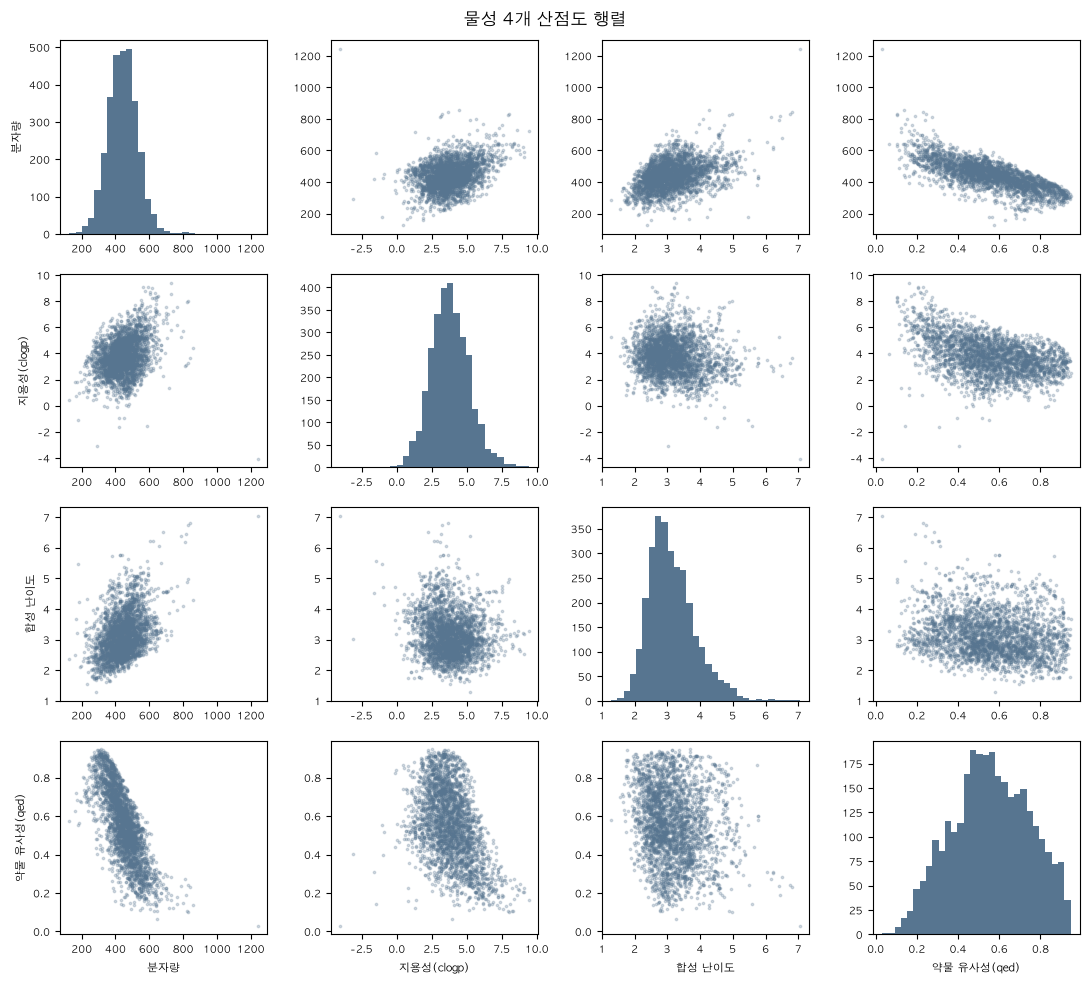

In [17]:
s=train.sample(3000,random_state=0)
fig,ax=plt.subplots(4,4,figsize=(11,10))
for i,r in enumerate(NUM):
    for j,c in enumerate(NUM):
        a=ax[i,j]
        if i==j:
            a.hist(s[r],bins=30,color='#577590')
        else:
            a.scatter(s[c],s[r],s=3,alpha=.25,c='#577590')
        if i==3: a.set_xlabel(nm[c],fontsize=8)
        if j==0: a.set_ylabel(nm[r],fontsize=8)
        a.tick_params(labelsize=7)
plt.suptitle('물성 4개 산점도 행렬'); plt.tight_layout(); plt.show()

#### 그래프 5 · 물성 산점도 행렬
- **발견**: 분자량↔약물 유사성 칸만 뚜렷한 내리막 띠입니다. 나머지 칸은 구름처럼 퍼져 있어 관계가 약합니다.
- **근거**: 상관계수는 분자량↔약물 유사성 **-0.75**, 분자량↔합성 난이도 0.41, 지용성↔약물 유사성 -0.44, 분자량↔지용성 0.34, 나머지는 약 -0.15입니다.
- **이유**: 약물 유사성 점수는 분자량 같은 성질을 이용해 계산되는 점수로 알려져 있어서 두 값이 엮이는 것은 자연스럽습니다. 큰 분자일수록 만들기 어렵다는 것도 상식과 맞습니다. (이 데이터의 qed 계산 방식은 확인하지 못했습니다.)
- **의미**: 두 값은 **부분적으로 겹칩니다.** 상관 -0.75는 분자량이 qed 변동의 약 56%(r²)를 설명한다는 뜻이고, 나머지 약 44%는 분자량으로 설명되지 않는 별도 정보입니다. 그래서 둘 중 하나를 버리기보다 **둘 다 쓰는 편이 낫습니다** (두 변수 기준 VIF 약 2.3으로, 흔히 문제 삼는 5~10보다 낮음). 선형 모델에서 계수를 해석할 때만 두 값이 같이 움직인다는 점에 유의하세요.

## 5. 물성 ↔ 물성: 상관계수 (피어슨 vs 스피어만)
- **피어슨**: 직선 관계를 봅니다. **스피어만**: 순서(크다/작다)만 봐서 이상치에 덜 민감합니다. 둘이 비슷하면 관계가 안정적이라는 뜻입니다.

**값 읽는 법 (피어슨·스피어만 공통, -1 ~ +1)**

| 값 | 의미 | 예시 |
|---|---|---|
| **+1** | 완벽한 양의 관계: 하나가 커지면 다른 것도 항상 커짐 | 키↑ → 몸무게↑ |
| **0** | 관계 없음: 한쪽을 알아도 다른 쪽을 알 수 없음 | 키 ↔ 시험 점수 |
| **-1** | 완벽한 음의 관계: 하나가 커지면 다른 것은 항상 작아짐 | 달린 거리↑ → 남은 체력↓ |

- 부호는 **방향**(+ 같이 증가 / - 반대로 움직임), 절댓값은 **강도**를 뜻합니다. 대략 0.1~0.3 약함, 0.3~0.5 중간, 0.5~0.7 강함, 0.7 이상 매우 강함으로 봅니다(공식 기준은 아니고 흔히 쓰는 어림 기준).
- 피어슨은 점이 **직선**에 얼마나 가까운지, 스피어만은 **순위가 얼마나 같이 움직이는지**를 봅니다. 그래서 곡선처럼 휘어도 한 방향이면 스피어만이 더 크게 나올 수 있습니다.
- 상관이 높다고 한쪽이 다른 쪽의 **원인**이라는 뜻은 아닙니다.

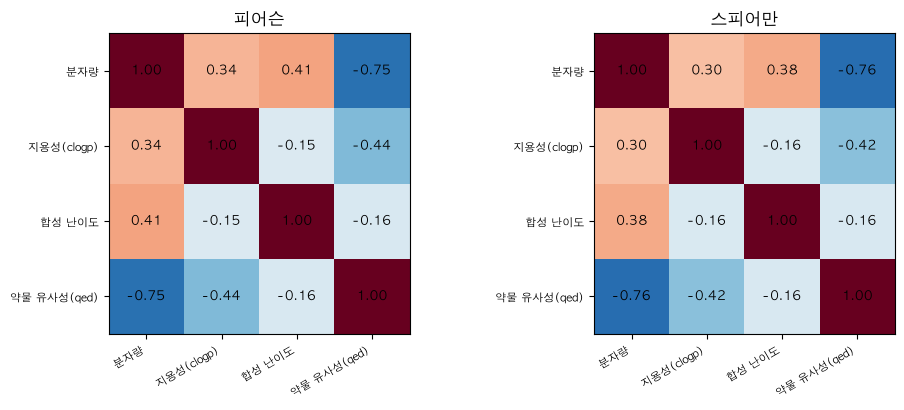

In [18]:
fig,ax=plt.subplots(1,2,figsize=(10,4.2))
for a,(m,t) in zip(ax,[('pearson','피어슨'),('spearman','스피어만')]):
    cm=train[NUM].corr(m); im=a.imshow(cm,cmap='RdBu_r',vmin=-1,vmax=1)
    l=[nm[c] for c in NUM]; a.set_xticks(range(4)); a.set_xticklabels(l,rotation=30,ha='right',fontsize=8); a.set_yticks(range(4)); a.set_yticklabels(l,fontsize=8)
    for i in range(4):
        for j in range(4): a.text(j,i,f'{cm.iloc[i,j]:.2f}',ha='center',va='center',fontsize=9)
    a.set_title(t)
plt.tight_layout(); plt.show()

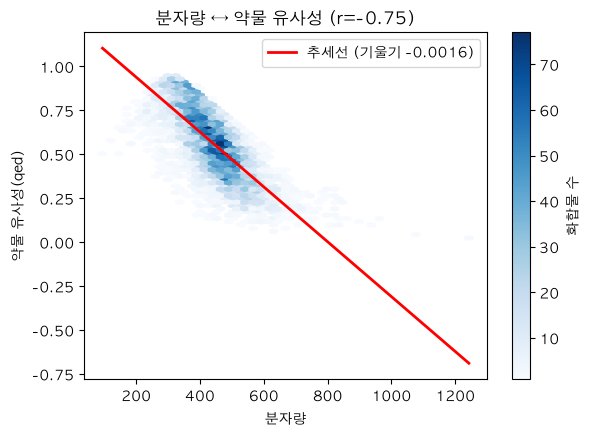

In [19]:
# 가장 강한 관계(분자량↔약물 유사성)를 직선과 함께
x,y=train.MolWt,train.qed
k=np.polyfit(x,y,1)
plt.figure(figsize=(6.5,4.5)); plt.hexbin(x,y,gridsize=45,cmap='Blues',mincnt=1); plt.colorbar(label='화합물 수')
xs=np.linspace(x.min(),x.max(),50); plt.plot(xs,np.polyval(k,xs),'r-',lw=2,label=f'추세선 (기울기 {k[0]:.4f})')
plt.xlabel('분자량'); plt.ylabel('약물 유사성(qed)'); plt.legend(); plt.title('분자량 ↔ 약물 유사성 (r=%.2f)'%np.corrcoef(x,y)[0,1]); plt.show()

#### 그래프 6 · 피어슨 vs 스피어만 / 그래프 7 · 분자량↔약물 유사성
- **발견**: 두 방식의 상관계수가 거의 같고, 분자량이 100 늘 때마다 약물 유사성이 약 0.16 내려갑니다.
- **근거**: 분자량↔약물 유사성은 피어슨 -0.75, 스피어만 -0.76. 분자량↔지용성은 0.34 vs 0.30, 분자량↔합성 난이도는 0.41 vs 0.38, 지용성↔약물 유사성은 -0.44 vs -0.42입니다. 추세선 기울기는 100당 -0.156입니다.
- **이유**: 이상치에 약한 피어슨과 순위 기반 스피어만이 일치한다는 것은 이 관계가 **일부 튀는 값 때문이 아니라 전체적으로 안정적**이라는 뜻입니다.
- **의미**: 분자량↔약물 유사성의 겹침은 우연이 아니라 안정적입니다. 다만 **겹치는 것은 일부(약 56%)** 라서, 육각 히스토그램에서 보듯 같은 분자량에서도 qed가 넓게 퍼져 있습니다. 즉 분자량이 qed를 대체할 수는 없으므로 둘 다 사용하는 쪽이 맞습니다(그래프 5와 같은 결론).

##### 핵심 분석 ④ MolWt ↔ qed (물성끼리의 관계)
**발견**
- 분자량이 클수록 qed가 낮아짐: 분자량 100 증가당 qed 약 0.16 감소 (r ≈ -0.75)

**근거**
- 피어슨 -0.75, 스피어만 -0.76으로 거의 동일 → 일부 이상치 때문이 아닌 안정적 관계
- 산점도 행렬과 육각 히스토그램(그래프 5, 7)

**이유 (추정)**
- qed 점수는 분자량 같은 성질을 이용해 계산되는 점수로 알려져 있어 두 값이 엮이는 것이 자연스러움 (이 데이터의 qed 계산 방식은 확인하지 못함)

**의미**
- 두 피처는 부분적으로 겹침 (r² ≈ 0.56: qed 변동의 약 56%만 분자량으로 설명되고 약 44%는 별도 정보)
- 같은 분자량에서도 qed가 넓게 퍼져 있어 분자량으로 qed를 대체할 수는 없음 → 둘 다 모델에 사용
- 선형 모델에서 계수를 해석할 때만 두 값이 함께 움직인다는 점에 유의

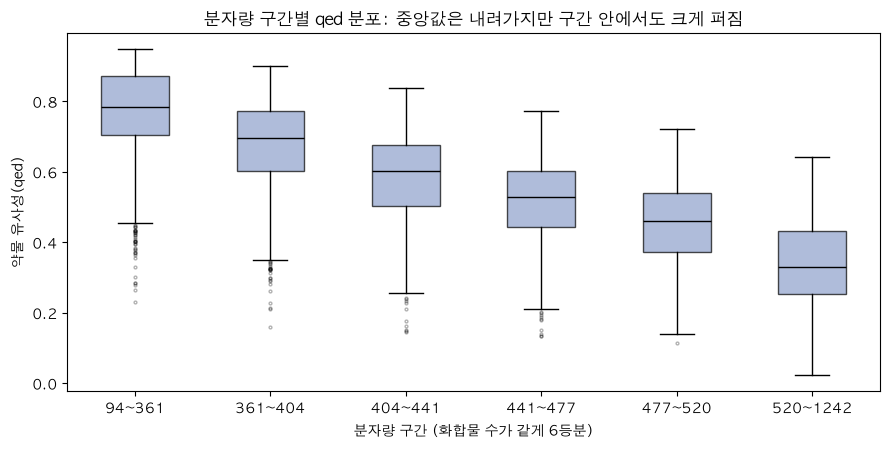

  94~ 361: 중앙값 0.79 | 가운데 50% 범위 0.70~0.87 | 최소~최대 0.23~0.95
 361~ 404: 중앙값 0.70 | 가운데 50% 범위 0.60~0.77 | 최소~최대 0.16~0.90
 404~ 441: 중앙값 0.60 | 가운데 50% 범위 0.50~0.68 | 최소~최대 0.14~0.84
 441~ 477: 중앙값 0.53 | 가운데 50% 범위 0.44~0.60 | 최소~최대 0.13~0.77
 477~ 520: 중앙값 0.46 | 가운데 50% 범위 0.37~0.54 | 최소~최대 0.11~0.72
 520~1242: 중앙값 0.33 | 가운데 50% 범위 0.25~0.43 | 최소~최대 0.02~0.64
r² = 0.56


In [20]:
# 보충 E. 같은 분자량 구간 안에서 qed는 얼마나 퍼져 있나 (일부만 겹친다는 증거)
mb=pd.qcut(train.MolWt,6)
groups=[train.qed[mb==c] for c in mb.cat.categories]
fig,ax=plt.subplots(figsize=(9,4.6))
bp=ax.boxplot(groups,patch_artist=True,showfliers=True,flierprops=dict(markersize=2,alpha=.3),tick_labels=[f'{int(c.left)}~{int(c.right)}' for c in mb.cat.categories])
for bx in bp['boxes']: bx.set_facecolor('#8da0cb'); bx.set_alpha(.7)
for md in bp['medians']: md.set_color('k')
ax.set_xlabel('분자량 구간 (화합물 수가 같게 6등분)'); ax.set_ylabel('약물 유사성(qed)'); ax.set_title('분자량 구간별 qed 분포: 중앙값은 내려가지만 구간 안에서도 크게 퍼짐')
plt.tight_layout(); plt.show()
for c,gq in zip(mb.cat.categories,groups): print(f'{int(c.left):4d}~{int(c.right):4d}: 중앙값 {gq.median():.2f} | 가운데 50% 범위 {gq.quantile(.25):.2f}~{gq.quantile(.75):.2f} | 최소~최대 {gq.min():.2f}~{gq.max():.2f}')
print('r² = %.2f'%(np.corrcoef(train.MolWt,train.qed)[0,1]**2))

##### 핵심 분석 ④-2 분자량↔qed가 "일부 겹친다"는 것의 의미
**발견**
- 분자량이 클수록 qed 중앙값은 뚜렷하게 내려감: 가장 가벼운 구간 0.79 → 가장 무거운 구간 0.33
- 그런데 **같은 분자량 구간 안에서도 qed가 넓게 퍼짐**: 가운데 50% 범위 폭이 구간마다 약 0.17, 각 구간 안의 최소~최대 폭도 0.6~0.7 정도
- 인접 구간의 상자들이 서로 많이 겹침 → 분자량을 알아도 qed를 정확히 맞힐 수는 없음 (r² = 0.56)

**근거**
- 그래프 7b: 분자량 6구간별 qed 상자그림
- 그래프 7: 분자량↔qed 육각 히스토그램(점이 띠 모양으로 퍼짐)

**이유 (추정)**
- qed는 분자량 외에 지용성 등 다른 성질도 함께 반영해 계산되는 점수로 알려져 있어서, 분자량이 같아도 다른 성질이 다르면 qed가 달라짐 (clogp와도 -0.44의 상관이 있음)

**의미**
- "겹친다" = **분자량이 qed 변동의 약 56%를 설명**하고, 나머지 약 44%는 분자량과 별개인 정보라는 뜻
- 그래서 qed를 분자량으로 대체하거나, 분자량 때문에 qed를 빼면 정보를 잃음 → 둘 다 사용
- 분자량은 독성과 무관한데(상관 0.006) qed는 독성과 관련이 있으므로(qed 0.4 미만에서 독성 비율 상승), qed의 독성 신호는 분자량으로 설명되는 부분보다 **그 밖의 부분에서 나올 가능성이 큼** (추정)

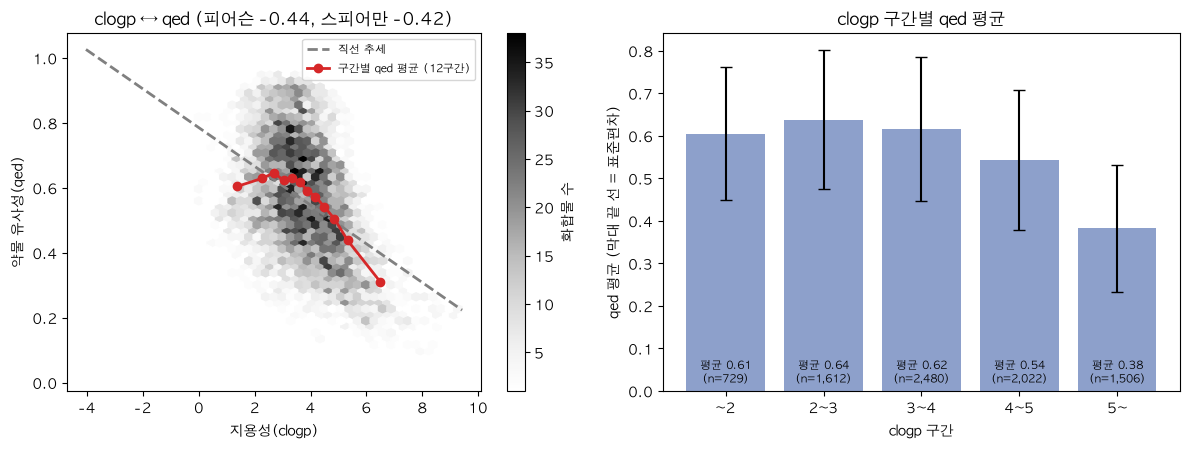

In [21]:
# 보충 C. clogp ↔ qed 관계: 밀도 + 구간 평균선 (직선이 아닌지 확인)
x,y=train.clogp,train.qed
r_p=np.corrcoef(x,y)[0,1]; r_s=stats.spearmanr(x,y)[0]
edges=np.quantile(x,np.linspace(0,1,13))
mid=[x[(x>=a)&(x<=b)].mean() for a,b in zip(edges[:-1],edges[1:])]
mq=[y[(x>=a)&(x<=b)].mean() for a,b in zip(edges[:-1],edges[1:])]
k=np.polyfit(x,y,1); xs=np.linspace(x.min(),x.max(),50)
fig,ax=plt.subplots(1,2,figsize=(12,4.6))
hb=ax[0].hexbin(x,y,gridsize=45,cmap='Greys',mincnt=1); fig.colorbar(hb,ax=ax[0],label='화합물 수')
ax[0].plot(xs,np.polyval(k,xs),'--',color='gray',lw=2,label='직선 추세')
ax[0].plot(mid,mq,'o-',color=C0,lw=2,label='구간별 qed 평균 (12구간)')
ax[0].set_xlabel('지용성(clogp)'); ax[0].set_ylabel('약물 유사성(qed)'); ax[0].legend(fontsize=8)
ax[0].set_title(f'clogp ↔ qed (피어슨 {r_p:.2f}, 스피어만 {r_s:.2f})')
cut=pd.cut(x,[-99,2,3,4,5,99],labels=['~2','2~3','3~4','4~5','5~'])
g=y.groupby(cut,observed=True).agg(['mean','std','size'])
ax[1].bar(g.index.astype(str),g['mean'],yerr=g['std'],capsize=4,color='#8da0cb')
for i,(m_,n_) in enumerate(zip(g['mean'],g['size'])): ax[1].text(i,0.02,f'평균 {m_:.2f}\n(n={n_:,})',ha='center',fontsize=8)
ax[1].set_xlabel('clogp 구간'); ax[1].set_ylabel('qed 평균 (막대 끝 선 = 표준편차)'); ax[1].set_title('clogp 구간별 qed 평균')
plt.tight_layout(); plt.show()

##### 핵심 분석 ⑤ clogp ↔ qed (물성끼리의 관계)
**발견**
- 두 물성은 중간 정도의 음의 상관: 피어슨 **-0.44**, 스피어만 -0.42 (가장 강한 짝은 분자량↔qed -0.75)
- 관계가 **직선이 아님**: clogp 4 이하에서는 qed 평균이 0.61~0.64로 거의 일정하다가, 4~5에서 0.54, **5 이상에서 0.38로 급락**

| clogp 구간 | ~2 | 2~3 | 3~4 | 4~5 | 5~ |
| --- | --- | --- | --- | --- | --- |
| qed 평균 | 0.61 | 0.64 | 0.62 | 0.54 | 0.38 |
| 화합물 수 | 729 | 1,612 | 2,480 | 2,022 | 1,506 |

**근거**
- 밀도 + 구간 평균선 그래프: 구간 평균선(빨강)이 직선 추세(점선)에서 벗어나 오른쪽 끝에서 꺾임
- 구간별 qed 평균 막대그래프 (막대 끝 선은 표준편차: 구간 안에서도 qed가 넓게 퍼져 있음)

**이유 (추정)**
- qed는 지용성 등 여러 성질로 계산되는 점수로 알려져 있고, 지용성이 지나치게 높으면 점수가 깎이는 구조일 가능성이 큼 (이 데이터의 qed 계산 방식은 확인하지 못함)
- clogp 5 부근에서 qed가 꺾이는 것은 Lipinski의 clogp 5 이하 권장 기준과 위치가 비슷함

**의미**
- 두 피처는 부분적으로 중복되지만 상관 -0.44는 다중공선성으로 문제 삼을 수준은 아님 → 둘 다 모델에 사용 가능
- 관계가 직선이 아니므로 선형 모델보다 트리 계열 모델이 적합
- clogp가 5를 넘는 화합물은 qed도 낮은 경우가 많아, 두 값이 모두 높은 조합은 드묾

## 6. 지문 ↔ 독성: 어떤 비트가 독성과 관련 있나
각 비트(입체 정보를 반영한 ECFPC 1,024칸 + FCFPC 1,024칸 + 변하지 않는 열을 뺀 PTFP 975칸)가 **켜졌을 때(1)와 꺼졌을 때(0)** 독성 있음 비율이 얼마나 다른지 카이제곱 검정으로 봅니다.

In [22]:
rows=[]
for c in FP_CHIRAL:
    x=train_chiral[c]
    if x.nunique()<2: continue
    chi,p,_,_=stats.chi2_contingency(pd.crosstab(x,train_chiral[TARGET]))
    rows.append((c,p,x.mean(),1-train_chiral[x==1][TARGET].mean(),1-train_chiral[x==0][TARGET].mean()))
r=pd.DataFrame(rows,columns=['비트','p값','켜진 비율','켜졌을때 독성있음비율','꺼졌을때 독성있음비율']).sort_values('p값')
n=len(r)
print('검정한 비트 수:',n)
print('p<0.05 인 비트:',(r.p값<0.05).sum(),'개 (우연히도 약 %d개는 나올 수 있음)'%int(n*0.05))
print('보정 후(Bonferroni)에도 유의한 비트:',(r.p값<0.05/n).sum(),'개')
r.head(10).round(3).reset_index(drop=True)

검정한 비트 수: 3023
p<0.05 인 비트: 1405 개 (우연히도 약 151개는 나올 수 있음)
보정 후(Bonferroni)에도 유의한 비트: 447 개


,비트,p값,켜진 비율,켜졌을때 독성있음비율,꺼졌을때 독성있음비율
0,ecfpc_807,0.0,0.632,0.384,0.579
1,fcfpc_146,0.0,0.042,0.881,0.437
2,ecfpc_650,0.0,0.756,0.406,0.613
3,fcfpc_18,0.0,0.484,0.546,0.372
4,ecfpc_425,0.0,0.053,0.820,0.436
5,ecfpc_893,0.0,0.554,0.381,0.550
6,fcfpc_526,0.0,0.051,0.811,0.437
7,ptfp_376,0.0,0.070,0.755,0.434
8,ptfp_284,0.0,0.060,0.776,0.436
9,fcfpc_445,0.0,0.033,0.894,0.441


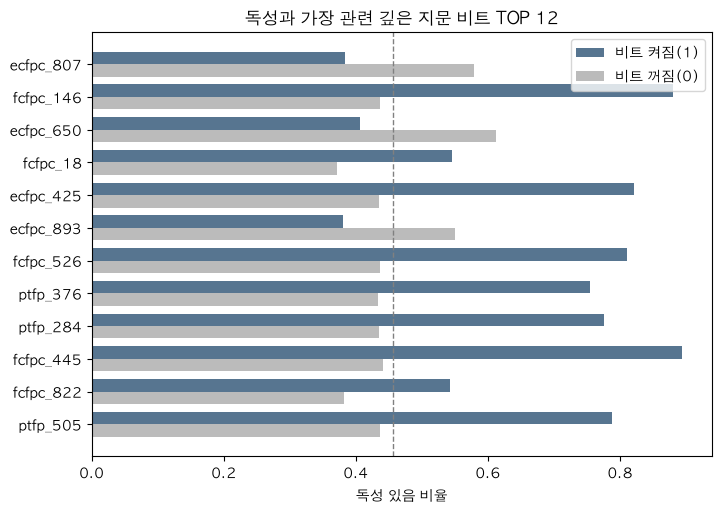

In [23]:
top=r.head(12).iloc[::-1]
y=np.arange(len(top)); h=.38
plt.figure(figsize=(8,5.5))
plt.barh(y+h/2,top['켜졌을때 독성있음비율'],h,color='#577590',label='비트 켜짐(1)')
plt.barh(y-h/2,top['꺼졌을때 독성있음비율'],h,color='#bbbbbb',label='비트 꺼짐(0)')
plt.axvline(1-train[TARGET].mean(),color='gray',ls='--',lw=1)
plt.yticks(y,top['비트']); plt.xlabel('독성 있음 비율'); plt.legend(); plt.title('독성과 가장 관련 깊은 지문 비트 TOP 12'); plt.show()

#### 그래프 8 · 독성과 관련 깊은 지문 비트 TOP 12
- **발견**: 비트가 켜졌느냐에 따라 독성 있음 비율이 크게 갈리는 비트가 있습니다.
- **근거**: `ecfpc_807`은 켜짐 38.4% vs 꺼짐 57.9%, `fcfpc_146`은 켜짐 **88.1%** vs 꺼짐 43.7%입니다. 3,023개 비트를 검정해 우연을 감안한 엄격한 기준(Bonferroni)에서도 **447개**가 유의합니다(켜지면 독성이 올라가는 쪽 189개, 내려가는 쪽 258개. ECFPC 141, FCFPC 133, PTFP 173개).
- **이유**: 어떤 부분 구조가 있으면 독성이 달라진다는 뜻으로 읽을 수 있지만, 비트 번호가 실제로 어떤 화학 구조인지는 이 데이터에서 알 수 없습니다.
- **의미**: 지문에는 독성과 관련된 정보가 실제로 들어 있고, 하나만 보면 약하지만 수백 개가 모이면 모델에 큰 힘이 됩니다. 이것이 지문을 쓸 때 F1이 0.70에서 0.82로 오르는 이유로 보입니다 (이 F1은 입체 정보 반영 전 기존 지문으로 측정했고, 새 지문으로는 다시 측정하지 않았습니다).

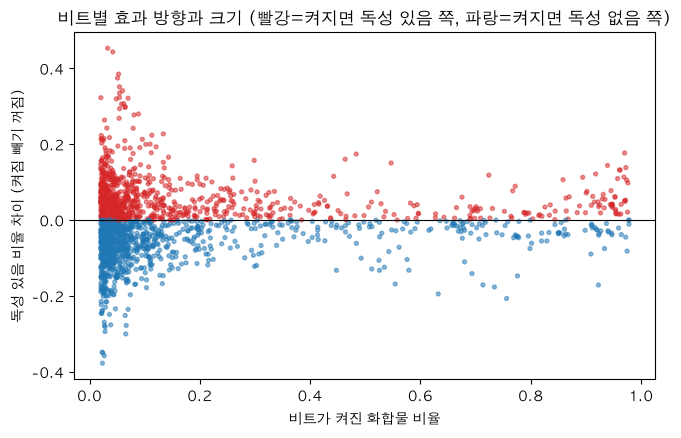

In [24]:
# 켜진 비율이 너무 작지 않은 비트들 중, 차이가 큰 쪽을 효과 방향별로 비교
big=r[(r['켜진 비율']>0.02)&(r['켜진 비율']<0.98)].copy()
big['차이']=big['켜졌을때 독성있음비율']-big['꺼졌을때 독성있음비율']
plt.figure(figsize=(7.5,4.5))
plt.scatter(big['켜진 비율'],big['차이'],s=8,alpha=.5,c=np.where(big['차이']>0,C0,C1))
plt.axhline(0,color='k',lw=.8); plt.xlabel('비트가 켜진 화합물 비율'); plt.ylabel('독성 있음 비율 차이 (켜짐 빼기 꺼짐)')
plt.title('비트별 효과 방향과 크기 (빨강=켜지면 독성 있음 쪽, 파랑=켜지면 독성 없음 쪽)'); plt.show()

#### 그래프 9 · 비트별 효과 방향과 크기
- **발견**: 점이 0 위(빨강, 켜지면 독성 있음 비율↑)와 아래(파랑, 켜지면 독성 있음 비율↓) 양쪽에 퍼져 있습니다. 그리고 차이가 큰 점은 켜진 비율이 낮은 왼쪽에 몰립니다.
- **근거**: 유의한 447개 중 독성 있음 쪽(위) 189개, 독성 없음 쪽(아래) 258개입니다. 켜짐-꺼짐 차이가 15%p를 넘는 비트 547개 중 **408개는 켜진 화합물이 10% 미만**입니다.
- **이유**: 독성을 높이는 구조와 낮추는 구조가 모두 있다는 뜻입니다. 희귀한 비트는 소수 화합물의 비율이라 크게 출렁이기 쉬워서 차이가 커 보일 수 있습니다. 예를 들어 `fcfpc_164`는 차이가 +0.54로 가장 크지만 켜진 화합물이 2개뿐이라 p=0.40으로 유의하지 않습니다.
- **의미**: 이 그림의 맨 끝 점들을 "중요한 구조"라고 곧바로 믿으면 안 됩니다. 표본이 충분하고 유의한 비트(그래프 8)를 우선하세요. 희귀 비트는 모델링에서 제거하거나 규제를 거는 것을 고려할 수 있습니다.

findfont: Failed to find font weight bold for AppleGothic, now using 400.


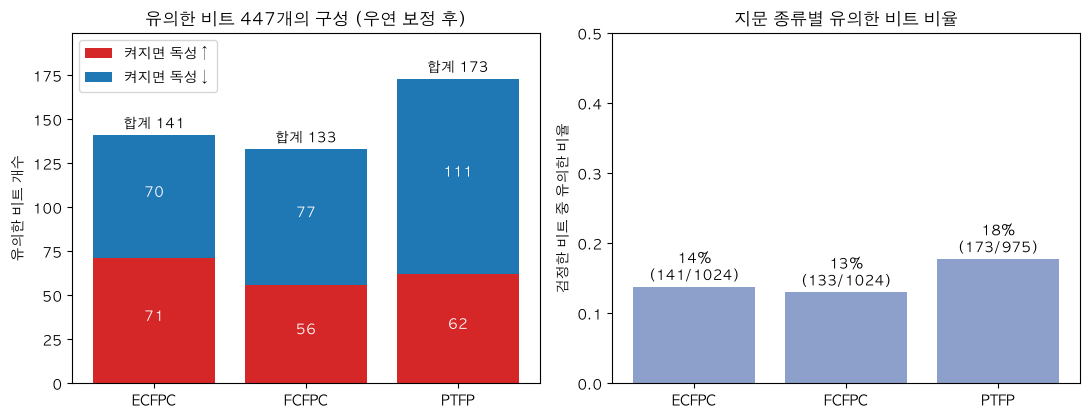

방향     켜지면 독성↑  켜지면 독성↓
비트                     
ECFPC       71       70
FCFPC       56       77
PTFP        62      111
{'ECFPC': 0.138, 'FCFPC': 0.13, 'PTFP': 0.177}


In [25]:
# 보충 F. 유의한 비트(447개)의 구성: 지문 종류 x 효과 방향
typ=r['비트'].str.split('_').str[0].map({'ecfpc':'ECFPC','fcfpc':'FCFPC','ptfp':'PTFP'})
sig=r[r['p값']<0.05/len(r)].copy(); sig['방향']=np.where(sig['켜졌을때 독성있음비율']>sig['꺼졌을때 독성있음비율'],'켜지면 독성↑','켜지면 독성↓')
ct=pd.crosstab(typ[sig.index],sig['방향']).reindex(['ECFPC','FCFPC','PTFP'])
tested=typ.value_counts().reindex(['ECFPC','FCFPC','PTFP'])
fig,ax=plt.subplots(1,2,figsize=(11,4.3))
bottom=np.zeros(3)
for col,color in [('켜지면 독성↑',C0),('켜지면 독성↓',C1)]:
    ax[0].bar(ct.index,ct[col],bottom=bottom,color=color,label=col)
    for i,(v,b) in enumerate(zip(ct[col],bottom)): ax[0].text(i,b+v/2,str(v),ha='center',color='white',fontweight='bold')
    bottom+=ct[col].values
for i,tot in enumerate(bottom): ax[0].text(i,tot+4,f'합계 {int(tot)}',ha='center')
ax[0].set_ylabel('유의한 비트 개수'); ax[0].set_title(f'유의한 비트 {len(sig)}개의 구성 (우연 보정 후)'); ax[0].legend(); ax[0].set_ylim(0,bottom.max()*1.15)
share=(ct.sum(axis=1)/tested)
ax[1].bar(share.index,share.values,color='#8da0cb')
for i,(s_,n_,k_) in enumerate(zip(share.values,tested.values,ct.sum(axis=1).values)): ax[1].text(i,s_+.01,f'{s_:.0%}\n({k_}/{n_})',ha='center')
ax[1].set_ylim(0,.5); ax[1].set_ylabel('검정한 비트 중 유의한 비율'); ax[1].set_title('지문 종류별 유의한 비트 비율')
plt.tight_layout(); plt.show()
print(ct); print((ct.sum(axis=1)/tested).round(3).to_dict())

##### 핵심 분석 ⑥ 지문 비트
**발견**
- 비트가 켜졌는지에 따라 독성 비율이 크게 달라지는 비트가 있음
  - `fcfpc_146`: 켜지면 독성 88.1% vs 꺼지면 43.7%
  - `ecfpc_807`: 켜지면 38.4% vs 꺼지면 57.9%
- 켜지면 독성이 올라가는 비트도, 내려가는 비트도 있음

**근거**
- 3,023개 비트 카이제곱 검정: 엄격한 기준(Bonferroni)에서도 447개 유의 (독성↑ 189개, 독성↓ 258개)
- 차이가 큰 비트의 상당수(547개 중 408개)는 켜진 화합물이 10% 미만인 희귀 비트 → 표본이 작아 우연일 수 있음

**이유 (추정)**
- 특정 부분 구조가 독성과 연관될 수 있음 (비트 번호가 어떤 구조인지는 이 데이터로는 알 수 없음)

**의미**
- 비트 하나는 약하지만 많이 모이면 힘이 됨 → 지문 포함 시 F1 0.70 → 0.82 (기존 지문 기준 측정, 새 지문으로는 재측정 안 함)
- 희귀 비트는 신뢰도가 낮으므로 제거 또는 규제 고려

## 7. 지문 ↔ 물성: 구조가 복잡하면 물성은 어떻게 되나
화합물 하나에서 **켜진 비트 개수**는 "구조가 얼마나 복잡한가"의 대략적인 척도입니다. 이것이 물성과 어떤 관계인지 봅니다.

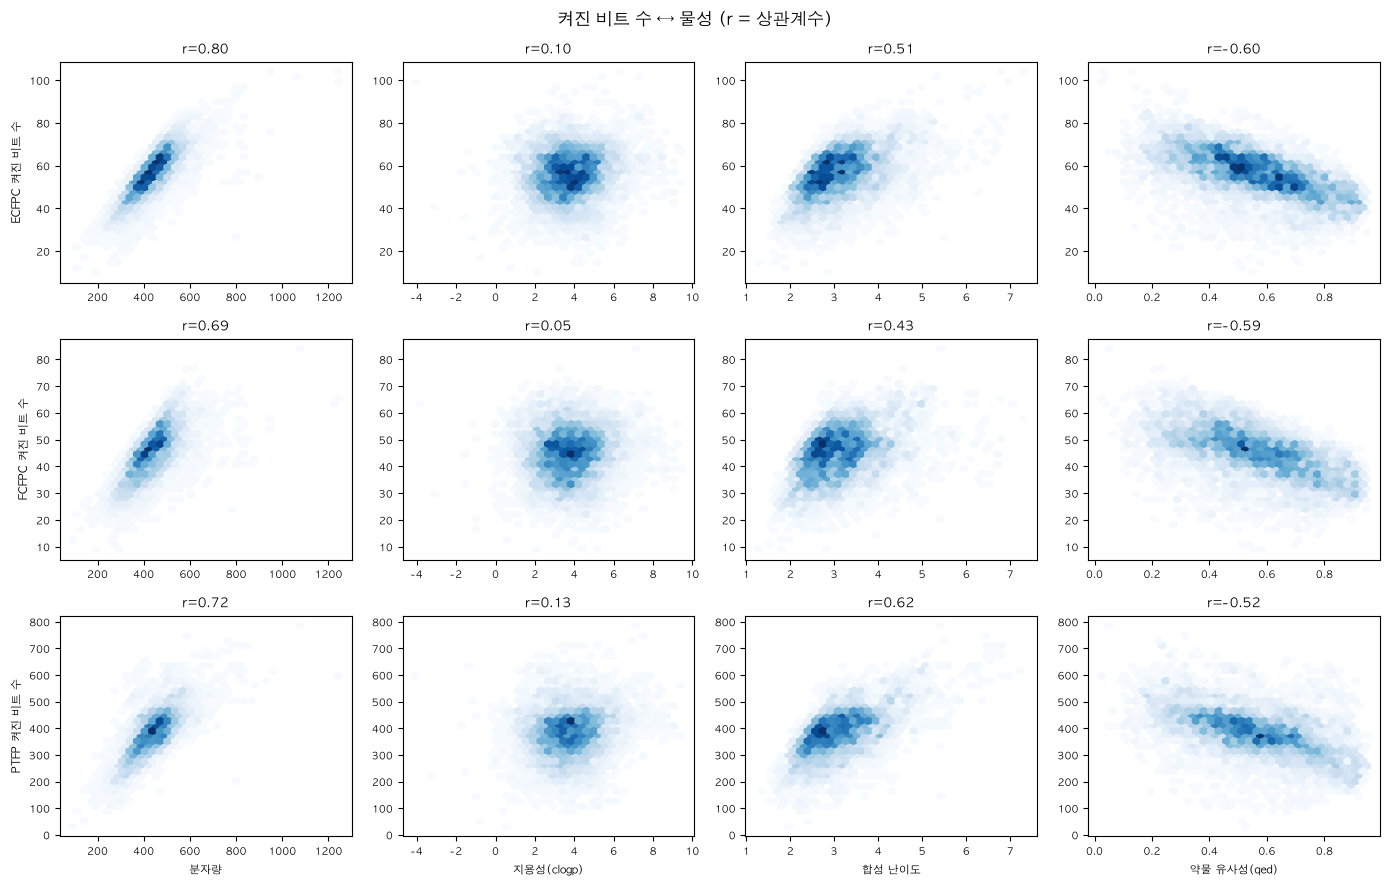

In [26]:
cnt=pd.DataFrame({p.upper():train_chiral[[c for c in FP_CHIRAL if c.startswith(p+'_')]].sum(axis=1) for p in ['ecfpc','fcfpc','ptfp']})
fig,ax=plt.subplots(3,4,figsize=(14,9))
for i,p in enumerate(cnt):
    for j,c in enumerate(NUM):
        a=ax[i,j]; a.hexbin(train[c],cnt[p],gridsize=35,cmap='Blues',mincnt=1)
        r_=np.corrcoef(train[c],cnt[p])[0,1]; a.set_title(f'r={r_:.2f}',fontsize=9)
        if i==2: a.set_xlabel(nm[c],fontsize=8)
        if j==0: a.set_ylabel(p+' 켜진 비트 수',fontsize=8)
        a.tick_params(labelsize=7)
plt.suptitle('켜진 비트 수 ↔ 물성 (r = 상관계수)'); plt.tight_layout(); plt.show()

#### 그래프 10 · 켜진 비트 수 ↔ 물성
- **발견**: 켜진 비트가 많은 화합물은 대체로 무겁고, 합성이 어렵고, 약물 유사성이 낮습니다. 지용성과는 거의 무관합니다.
- **근거**: 켜진 비트 수와 분자량의 상관은 ECFPC 0.80, FCFPC 0.69, PTFP 0.72. 합성 난이도는 0.51 / 0.43 / 0.62, 약물 유사성은 -0.60 / -0.59 / -0.52, 지용성은 0.10 / 0.05 / 0.13입니다. 켜진 비트 수와 독성(label)의 상관은 0.01~0.02입니다.
- **이유**: 큰 분자일수록 가진 부분 구조가 많아서 켜진 칸도 늘어납니다. 그래서 켜진 비트 수는 "분자 크기"를 대신 알려 주는 값입니다.
- **의미**: 켜진 비트 수는 분자량과 상당 부분 겹치고 독성과도 무관해서 **새로운 변수로 만들 가치가 낮습니다.** 독성에 영향을 주는 정보는 개수가 아니라 **어떤 비트가 켜졌느냐**에 있습니다.

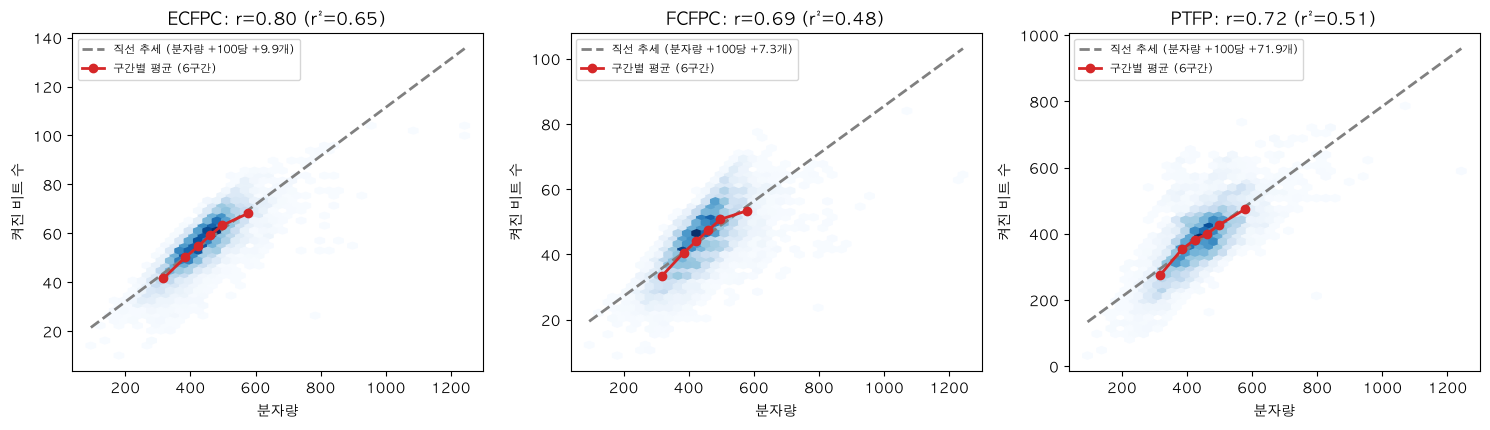

ECFPC 구간별 평균 켜진 비트 수: [41.6, 50.1, 54.7, 59.2, 63.2, 68.2]
ECFPC 분자량 100당 켜진 비트 수: [13.1, 13.1, 12.9, 12.9, 12.7, 11.8]
켜진 비트 수(ECFPC) ↔ 독성 상관: -0.021


In [27]:
# 보충 G. 분자량 ↔ 켜진 비트 수 (지문 종류별 추세와 구간 평균)
fig,ax=plt.subplots(1,3,figsize=(15,4.4))
for a,(pf,nm_) in zip(ax,[('ecfpc','ECFPC'),('fcfpc','FCFPC'),('ptfp','PTFP')]):
    cnt=train_chiral[[c for c in FP_CHIRAL if c.startswith(pf+'_')]].sum(axis=1); mw=train_chiral.MolWt
    a.hexbin(mw,cnt,gridsize=40,cmap='Blues',mincnt=1)
    k=np.polyfit(mw,cnt,1); xs=np.linspace(mw.min(),mw.max(),50); a.plot(xs,np.polyval(k,xs),'--',color='gray',lw=2,label=f'직선 추세 (분자량 +100당 {k[0]*100:+.1f}개)')
    b=pd.qcut(mw,6); g=cnt.groupby(b,observed=True).mean(); xm=mw.groupby(b,observed=True).mean()
    a.plot(xm,g,'o-',color=C0,lw=2,label='구간별 평균 (6구간)')
    r_=np.corrcoef(mw,cnt)[0,1]; a.set_title(f'{nm_}: r={r_:.2f} (r²={r_**2:.2f})'); a.set_xlabel('분자량'); a.set_ylabel('켜진 비트 수'); a.legend(fontsize=8,loc='upper left')
plt.tight_layout(); plt.show()
cnt=train_chiral[[c for c in FP_CHIRAL if c.startswith('ecfpc_')]].sum(axis=1); b=pd.qcut(train_chiral.MolWt,6)
print('ECFPC 구간별 평균 켜진 비트 수:',[round(v,1) for v in cnt.groupby(b,observed=True).mean()])
print('ECFPC 분자량 100당 켜진 비트 수:',[round(v,1) for v in (cnt.groupby(b,observed=True).mean()/train_chiral.MolWt.groupby(b,observed=True).mean()*100)])
print('켜진 비트 수(ECFPC) ↔ 독성 상관: %.3f'%np.corrcoef(cnt,1-train_chiral[TARGET])[0,1])

## 8. 이변량 분석 요약
| 짝 | 결과 |
|---|---|
| **지용성 ↔ 독성** | 가장 뚜렷. 지용성↑ → 독성 있음 비율↑ (효과 크기 중간) |
| 합성 난이도·약물 유사성 ↔ 독성 | 통계적으로는 유의하나 효과는 작음 |
| **분자량 ↔ 독성** | 관계 없음 |
| **분자량 ↔ 약물 유사성** | 강한 음의 관계(약 -0.75): 부분적으로 겹침(분자량이 qed 변동의 약 56% 설명) |
| 분자량 ↔ 켜진 비트 수 | 강한 양의 관계(약 0.7~0.8) |
| 지문 비트 ↔ 독성 | 일부 비트가 뚜렷하게 관련 (독성을 올리는 구조, 내리는 구조 둘 다 있음). 비트 하나로 충분하진 않음 |